In [1]:
# 1. Projecting paths and reproducibility

from pathlib import Path
import os
import sys
import random
import json
import time
import warnings

PROJECT_ROOT = Path(r"C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project")
DATASET_ROOT = Path(r"C:\Users\Kinjal Chatterjee\Downloads\MILK10k")

RANDOM_SEED = 42
TEST_SIZE = 0.20
VAL_SIZE = 0.20  # fraction of the full dataset

# Create output folders from scratch if they do not already exist.
for folder in [
    "data/processed", "splits", "checkpoints", "reports",
    "figures", "artifacts", "logs"
]:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import numpy as np
        np.random.seed(seed)
    except ImportError:
        pass
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_seed()

print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Dataset root:", DATASET_ROOT)
print("Dataset exists:", DATASET_ROOT.exists())
print("Python:", sys.version)


Project root: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Project exists: True
Dataset root: C:\Users\Kinjal Chatterjee\Downloads\MILK10k
Dataset exists: True
Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]


In [2]:
# 2. Checking required packages and compute device

import importlib.util

required = ["numpy", "pandas", "PIL", "sklearn", "matplotlib", "torch", "torchvision"]
missing = [p for p in required if importlib.util.find_spec(p) is None]
print("Missing packages:", missing if missing else "None")

if missing:
    print("\\nInstall missing packages in the VS Code terminal with:")
    print("python -m pip install " + " ".join(missing))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
print("CPU-only run:", DEVICE.type == "cpu")


Missing packages: None
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu
CPU-only run: True


In [3]:
# 3. Auditing the dataset folder

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_ROOT}\\n"
        "Edit DATASET_ROOT in Cell 1 to point to your MILK10k folder."
    )

all_files = [p for p in DATASET_ROOT.rglob("*") if p.is_file()]
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_files = [p for p in all_files if p.suffix.lower() in image_exts]
tabular_files = [p for p in all_files if p.suffix.lower() in {".csv", ".tsv", ".xlsx", ".json"}]

print(f"Total files: {len(all_files):,}")
print(f"Image files: {len(image_files):,}")
print(f"Annotation/tabular files: {len(tabular_files):,}")

print("\\nTop-level contents:")
for p in sorted(DATASET_ROOT.iterdir()):
    kind = "DIR " if p.is_dir() else "FILE"
    print(f"{kind}  {p.name}")

print("\\nImage extension counts:")
if image_files:
    print(pd.Series([p.suffix.lower() for p in image_files]).value_counts().to_string())

print("\\nAnnotation files:")
for p in tabular_files[:100]:
    print(" -", p.relative_to(DATASET_ROOT))


Total files: 10,486
Image files: 10,480
Annotation/tabular files: 4
\nTop-level contents:
FILE  attribution.txt
DIR   images
DIR   licenses
FILE  metadata.csv
DIR   supplements
\nImage extension counts:
.jpg    10480
\nAnnotation files:
 - metadata.csv
 - supplements\training_gt.csv
 - supplements\training_input.csv
 - supplements\training_supp.csv


In [4]:
# 4. Inspecting annotation files and their columns

def read_tabular_preview(path):
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path, nrows=8)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\\t", nrows=8)
    if suffix == ".xlsx":
        return pd.read_excel(path, nrows=8)
    if suffix == ".json":
        try:
            return pd.read_json(path).head(8)
        except ValueError:
            return pd.json_normalize(json.loads(path.read_text(encoding="utf-8"))).head(8)
    return None

annotation_previews = {}
for path in tabular_files:
    try:
        preview = read_tabular_preview(path)
        if preview is not None:
            annotation_previews[path] = preview
            print("\\n" + "=" * 90)
            print("FILE:", path.relative_to(DATASET_ROOT))
            print("COLUMNS:", list(preview.columns))
            print(preview.head(5).to_string(index=False))
    except Exception as exc:
        print(f"Could not preview {path.name}: {exc}")

print("\\nUse the output above to identify the lesion-level ground-truth file and metadata file.")


\n==========================================================================================
FILE: metadata.csv
COLUMNS: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']
     isic_id     attribution copyright_license  age_approx anatom_site_general  anatom_site_special  concomitant_biopsy diagnosis_1                                              diagnosis_2                       diagnosis_3  diagnosis_4 diagnosis_confirm_type image_manipulation         image_type  lesion_id melanocytic    sex
ISIC_0051817 MILK study team          CC-BY-NC          70     upper extremity                  NaN                True   Malignant                       Malignant epidermal proliferations Squamous cell carcinoma, Invasive          NaN         histopathology    ins

First 30 image paths:
 - images\ISIC_0051817.jpg
 - images\ISIC_0073863.jpg
 - images\ISIC_0075884.jpg
 - images\ISIC_0076255.jpg
 - images\ISIC_0077054.jpg
 - images\ISIC_0078190.jpg
 - images\ISIC_0078197.jpg
 - images\ISIC_0080019.jpg
 - images\ISIC_0080219.jpg
 - images\ISIC_0081055.jpg
 - images\ISIC_0082447.jpg
 - images\ISIC_0082638.jpg
 - images\ISIC_0082674.jpg
 - images\ISIC_0084581.jpg
 - images\ISIC_0084885.jpg
 - images\ISIC_0084958.jpg
 - images\ISIC_0089407.jpg
 - images\ISIC_0090512.jpg
 - images\ISIC_0091092.jpg
 - images\ISIC_0091477.jpg
 - images\ISIC_0091575.jpg
 - images\ISIC_0093135.jpg
 - images\ISIC_0093389.jpg
 - images\ISIC_0093873.jpg
 - images\ISIC_0094604.jpg
 - images\ISIC_0095743.jpg
 - images\ISIC_0096543.jpg
 - images\ISIC_0097262.jpg
 - images\ISIC_0097302.jpg
 - images\ISIC_0097629.jpg


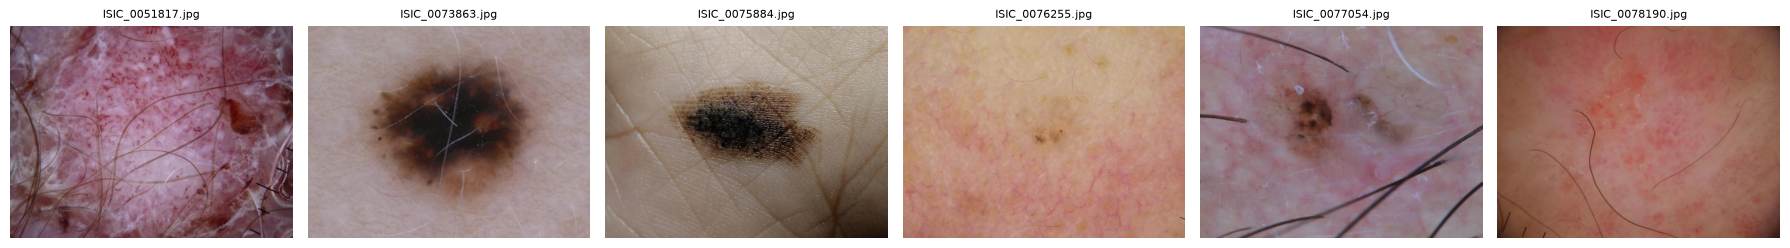

In [5]:
# 5. Inspecting image naming and folder patterns

print("First 30 image paths:")
for p in image_files[:30]:
    print(" -", p.relative_to(DATASET_ROOT))

# Show a few images so we can verify which image type is being used.
if image_files:
    sample_paths = image_files[:min(6, len(image_files))]
    fig, axes = plt.subplots(1, len(sample_paths), figsize=(3 * len(sample_paths), 3))
    if len(sample_paths) == 1:
        axes = [axes]
    for ax, path in zip(axes, sample_paths):
        try:
            ax.imshow(Image.open(path).convert("RGB"))
            ax.set_title(path.name[:24], fontsize=8)
            ax.axis("off")
        except Exception as exc:
            ax.set_title(f"Unreadable\\n{path.name[:15]}", fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No images found. Check DATASET_ROOT.")


In [6]:
gt = pd.read_csv(DATASET_ROOT / "supplements" / "training_gt.csv")
metadata = pd.read_csv(DATASET_ROOT / "metadata.csv")
train_input = pd.read_csv(DATASET_ROOT / "supplements" / "training_input.csv")

for name, df in [
    ("GROUND TRUTH", gt),
    ("METADATA", metadata),
    ("TRAINING INPUT", train_input)
]:
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


--- GROUND TRUTH ---
Shape: (5240, 12)
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']
 lesion_id  AKIEC  BCC  BEN_OTH  BKL  DF  INF  MAL_OTH  MEL  NV  SCCKA  VASC
IL_0000652      0    1        0    0   0    0        0    0   0      0     0
IL_0003176      0    1        0    0   0    0        0    0   0      0     0
IL_0004688      0    1        0    0   0    0        0    0   0      0     0

--- METADATA ---
Shape: (10480, 17)
Columns: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']
     isic_id     attribution copyright_license  age_approx anatom_site_general anatom_site_special  concomitant_biopsy diagnosis_1                        diagnosis_2                       diagnosis_3  diagnos

In [7]:
# 6. Dataset configuration

# Ground truth and metadata
GROUND_TRUTH_FILE = "supplements/training_gt.csv"
METADATA_FILE = "metadata.csv"

# Column configuration
LESION_ID_COLUMN = "lesion_id"
IMAGE_ID_COLUMN = "isic_id"
LABEL_COLUMN = None

CLASS_COLUMNS = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

IMAGE_TYPE_COLUMN = "image_type"
DERMOSCOPIC_VALUE = "dermoscopic"

CLASS_NAMES = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

print("Set GROUND_TRUTH_FILE, LESION_ID_COLUMN, and either LABEL_COLUMN or CLASS_COLUMNS.")
print("Current class count:", len(CLASS_NAMES))


Set GROUND_TRUTH_FILE, LESION_ID_COLUMN, and either LABEL_COLUMN or CLASS_COLUMNS.
Current class count: 11


In [8]:
# 7. Loading the configured annotations

def resolve_dataset_file(relative_path):
    if relative_path is None:
        return None
    path = Path(relative_path)
    return path if path.is_absolute() else DATASET_ROOT / path

def read_annotation(path):
    if path is None or not path.exists():
        raise FileNotFoundError(f"Annotation file not found: {path}")
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    if path.suffix.lower() == ".tsv":
        return pd.read_csv(path, sep="\\t")
    if path.suffix.lower() == ".xlsx":
        return pd.read_excel(path)
    if path.suffix.lower() == ".json":
        return pd.read_json(path)
    raise ValueError(f"Unsupported annotation format: {path.suffix}")

if GROUND_TRUTH_FILE is None:
    print("STOP: configure GROUND_TRUTH_FILE in Cell 6, then rerun this cell.")
else:
    ground_truth_path = resolve_dataset_file(GROUND_TRUTH_FILE)
    ground_truth = read_annotation(ground_truth_path)
    print("Ground-truth shape:", ground_truth.shape)
    print("Columns:", list(ground_truth.columns))
    display(ground_truth.head())


Ground-truth shape: (5240, 12)
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0,1,0,0,0,0,0,0,0,0,0
1,IL_0003176,0,1,0,0,0,0,0,0,0,0,0
2,IL_0004688,0,1,0,0,0,0,0,0,0,0,0
3,IL_0005081,0,0,0,0,0,0,0,0,0,1,0
4,IL_0006177,0,1,0,0,0,0,0,0,0,0,0


In [9]:
# 8. Building the lesion-level image/label table

def normalize_image_key(value):
    return Path(str(value)).stem.lower().strip()

if GROUND_TRUTH_FILE is None or LESION_ID_COLUMN is None:
    print("STOP: configure the ground-truth file and lesion ID column in Cell 6.")
elif LABEL_COLUMN is None and CLASS_COLUMNS is None:
    print("STOP: set LABEL_COLUMN or CLASS_COLUMNS in Cell 6.")
else:
    required_cols = [LESION_ID_COLUMN]
    if LABEL_COLUMN is not None:
        required_cols.append(LABEL_COLUMN)
    else:
        required_cols += list(CLASS_COLUMNS)
    missing_cols = [c for c in required_cols if c not in ground_truth.columns]
    if missing_cols:
        raise KeyError(f"Missing configured columns: {missing_cols}")

    # Establish one label row per lesion.
    if CLASS_COLUMNS is not None:
        y = ground_truth[CLASS_COLUMNS].to_numpy(dtype=np.float32)
        if y.shape[1] != len(CLASS_NAMES):
            raise ValueError("CLASS_COLUMNS must contain exactly 11 columns.")
        labels = np.argmax(y, axis=1)
        confidence = y.max(axis=1)
        if not np.allclose(y.sum(axis=1), 1):
            print("Warning: some one-hot rows do not sum to 1.")
    else:
        label_map = {name: i for i, name in enumerate(CLASS_NAMES)}
        labels = ground_truth[LABEL_COLUMN].astype(str).map(label_map)
        if labels.isna().any():
            unknown = sorted(ground_truth.loc[labels.isna(), LABEL_COLUMN].astype(str).unique())
            raise ValueError(f"Labels not in CLASS_NAMES: {unknown}")
        labels = labels.to_numpy(dtype=int)

    lesion_table = pd.DataFrame({
        "lesion_id": ground_truth[LESION_ID_COLUMN].astype(str),
        "label": labels
    }).drop_duplicates("lesion_id")

    print("Unique lesions:", lesion_table["lesion_id"].nunique())
    print("Class distribution:")
    print(lesion_table["label"].value_counts().sort_index())
    display(lesion_table.head())


Unique lesions: 5240
Class distribution:
label
0      303
1     2522
2       44
3      544
4       52
5       50
6        9
7      450
8      746
9      473
10      47
Name: count, dtype: int64


,lesion_id,label
0,IL_0000652,1
1,IL_0003176,1
2,IL_0004688,1
3,IL_0005081,9
4,IL_0006177,1


In [10]:
# 9. Create a leakage-safe lesion-level split

# Run after lesion_table has been created in Cell 8.
if "lesion_table" not in globals():
    print("Run and complete Cell 8 first.")
else:
    train_val, test_df = train_test_split(
        lesion_table,
        test_size=TEST_SIZE,
        random_state=RANDOM_SEED,
        stratify=lesion_table["label"]
    )
    relative_val_size = VAL_SIZE / (1 - TEST_SIZE)
    train_df, val_df = train_test_split(
        train_val,
        test_size=relative_val_size,
        random_state=RANDOM_SEED,
        stratify=train_val["label"]
    )

    split_map = {}
    for split_name, frame in [
        ("train", train_df), ("val", val_df), ("test", test_df)
    ]:
        for lesion_id in frame["lesion_id"]:
            split_map[lesion_id] = split_name

    split_df = lesion_table.copy()
    split_df["split"] = split_df["lesion_id"].map(split_map)

    # Explicit leakage check.
    sets = {
        name: set(frame["lesion_id"])
        for name, frame in [
            ("train", train_df), ("val", val_df), ("test", test_df)
        ]
    }
    assert not (sets["train"] & sets["val"])
    assert not (sets["train"] & sets["test"])
    assert not (sets["val"] & sets["test"])

    split_path = PROJECT_ROOT / "splits" / "lesion_level_split.csv"
    split_df.to_csv(split_path, index=False)

    print("Split sizes:", {k: len(v) for k, v in sets.items()})
    print("Saved:", split_path)
    display(pd.crosstab(split_df["split"], split_df["label"]))


Split sizes: {'train': 3144, 'val': 1048, 'test': 1048}
Saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\splits\lesion_level_split.csv


label,0,1,2,3,4,5,6,7,8,9,10
split,,,,,,,,,,,
test,61,504,9,109,10,10,2,90,149,95,9
train,182,1514,26,326,31,30,5,270,448,283,29
val,60,504,9,109,11,10,2,90,149,95,9


In [11]:

# 10. Mapping each lesion to its dermoscopic image

metadata = pd.read_csv(DATASET_ROOT / METADATA_FILE)

# Keep only dermoscopic images
dermoscopic = metadata[
    metadata[IMAGE_TYPE_COLUMN].astype(str).str.lower() == DERMOSCOPIC_VALUE
].copy()

# Match image IDs to actual image files
image_lookup = {
    path.stem.lower(): str(path)
    for path in image_files
}

dermoscopic["image_path"] = (
    dermoscopic[IMAGE_ID_COLUMN]
    .astype(str)
    .str.lower()
    .map(image_lookup)
)

# Check for missing image files
missing = dermoscopic["image_path"].isna().sum()
print("Dermoscopic images:", len(dermoscopic))
print("Missing image files:", missing)

# Keep only the columns we need
image_table = dermoscopic[
    [LESION_ID_COLUMN, IMAGE_ID_COLUMN, "image_path"]
].copy()

image_table = image_table.rename(columns={
    LESION_ID_COLUMN: "lesion_id",
    IMAGE_ID_COLUMN: "image_id"
})

# Attach labels and train/validation/test assignments
image_table["lesion_id"] = image_table["lesion_id"].astype(str)

final_df = image_table.merge(
    split_df[["lesion_id", "label", "split"]],
    on="lesion_id",
    how="inner",
    validate="one_to_one"
)

# Dataset integrity checks
assert missing == 0, "Some dermoscopic images could not be found."
assert final_df["lesion_id"].nunique() == len(final_df)
assert final_df["image_path"].notna().all()
assert final_df["split"].notna().all()

print("\nFinal dataset:", final_df.shape)
print(final_df["split"].value_counts())
print("\nClass distribution:")
print(pd.crosstab(final_df["split"], final_df["label"]))

# Save the image-level dataset index
index_path = PROJECT_ROOT / "data" / "processed" / "image_dataset.csv"
final_df.to_csv(index_path, index=False)

print("\nSaved dataset index to:", index_path)
display(final_df.head())


Dermoscopic images: 5240
Missing image files: 0

Final dataset: (5240, 5)
split
train    3144
val      1048
test     1048
Name: count, dtype: int64

Class distribution:
label   0     1   2    3   4   5   6    7    8    9   10
split                                                   
test    61   504   9  109  10  10   2   90  149   95   9
train  182  1514  26  326  31  30   5  270  448  283  29
val     60   504   9  109  11  10   2   90  149   95   9

Saved dataset index to: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\data\processed\image_dataset.csv


,lesion_id,image_id,image_path,label,split
0,IL_1612768,ISIC_0051817,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,9,val
1,IL_2547802,ISIC_0073863,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,8,train
2,IL_8089688,ISIC_0076255,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,1,val
3,IL_5271098,ISIC_0077054,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,1,train
4,IL_4115404,ISIC_0078190,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,0,val


In [12]:

# 11. Creating PyTorch Dataset and DataLoaders

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MILK10Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

train_data = final_df[final_df["split"] == "train"]
val_data = final_df[final_df["split"] == "val"]
test_data = final_df[final_df["split"] == "test"]

train_dataset = MILK10Dataset(train_data, train_transform)
val_dataset = MILK10Dataset(val_data, eval_transform)
test_dataset = MILK10Dataset(test_data, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Unique labels:", torch.unique(labels).tolist())
print("Device:", DEVICE)


Training batches: 99
Validation batches: 33
Testing batches: 33
Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
Unique labels: [0, 1, 3, 6, 7, 8, 9]
Device: cpu


In [13]:

# 12. Training and evaluation engine

from sklearn.metrics import f1_score
from pathlib import Path
import copy
import time
import numpy as np
import torch
import torch.nn as nn

NUM_CLASSES = len(CLASS_NAMES)

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

# Calculate class weights using training data only
class_counts = np.bincount(
    train_data["label"].to_numpy(),
    minlength=NUM_CLASSES
)

class_weights = len(train_data) / (
    NUM_CLASSES * np.maximum(class_counts, 1)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Class weights:", class_weights.cpu().numpy().round(3))


def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    average_loss = total_loss / len(loader.dataset)

    return average_loss, macro_f1, np.array(all_labels), np.array(all_predictions)


def train_model(model, train_loader, val_loader,
                model_name, epochs=5, learning_rate=1e-4):

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_f1 = -1.0
    history = []

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"

    for epoch in range(epochs):
        start_time = time.time()
        model.train()

        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        val_loss, val_f1, _, _ = evaluate_model(
            model, val_loader
        )

        elapsed = time.time() - start_time

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_macro_f1": val_f1,
            "seconds": elapsed
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1

            torch.save({
                "model_state_dict": model.state_dict(),
                "model_name": model_name,
                "num_classes": NUM_CLASSES,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "best_val_macro_f1": best_f1,
                "epoch": epoch + 1
            }, checkpoint_path)

            print("  Saved new best checkpoint.")

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        PROJECT_ROOT / "reports" / f"{model_name}_history.csv",
        index=False
    )

    print(f"\nBest validation Macro-F1: {best_f1:.4f}")
    print("Checkpoint:", checkpoint_path)

    return model, history_df


Class weights: [ 1.57   0.189 10.993  0.877  9.22   9.527 57.164  1.059  0.638  1.01
  9.856]


In [14]:

# 13. Initialize ResNet18

resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace classification layer
resnet18.fc = nn.Linear(
    resnet18.fc.in_features,
    NUM_CLASSES
)

# Freeze all layers
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer4 and classifier
for param in resnet18.layer4.parameters():
    param.requires_grad = True

for param in resnet18.fc.parameters():
    param.requires_grad = True

resnet18 = resnet18.to(DEVICE)

trainable_params = sum(
    p.numel() for p in resnet18.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable_params:,}")
print("Total parameters:", f"{sum(p.numel() for p in resnet18.parameters()):,}")
print("Device:", DEVICE)


Trainable parameters: 8,399,371
Total parameters: 11,182,155
Device: cpu


In [15]:

# 14. Training ResNet18

resnet18, resnet_history = train_model(
    model=resnet18,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="resnet18",
    epochs=5,
    learning_rate=1e-4
)

display(resnet_history)


Epoch 1/5 | Train Loss: 2.0673 | Val Loss: 1.7935 | Val Macro-F1: 0.2722 | Time: 95.6s
  Saved new best checkpoint.
Epoch 2/5 | Train Loss: 1.1724 | Val Loss: 1.7848 | Val Macro-F1: 0.3126 | Time: 109.9s
  Saved new best checkpoint.
Epoch 3/5 | Train Loss: 0.8221 | Val Loss: 1.8058 | Val Macro-F1: 0.3342 | Time: 55.3s
  Saved new best checkpoint.
Epoch 4/5 | Train Loss: 0.5895 | Val Loss: 1.8882 | Val Macro-F1: 0.3658 | Time: 54.0s
  Saved new best checkpoint.
Epoch 5/5 | Train Loss: 0.4538 | Val Loss: 2.0097 | Val Macro-F1: 0.3468 | Time: 50.1s

Best validation Macro-F1: 0.3658
Checkpoint: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_best.pth


,epoch,train_loss,val_loss,val_macro_f1,seconds
0,1,2.067284,1.793468,0.272203,95.581716
1,2,1.172405,1.784765,0.312593,109.922867
2,3,0.822092,1.805792,0.334192,55.258278
3,4,0.589531,1.888236,0.365815,53.970970
4,5,0.453815,2.009689,0.346826,50.096202


In [16]:

# 15. Load best ResNet18 checkpoint and evaluate on test set

checkpoint_path = CHECKPOINT_DIR / "resnet18_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

resnet18.load_state_dict(checkpoint["model_state_dict"])
resnet18 = resnet18.to(DEVICE)

test_loss, test_f1, y_true, y_pred = evaluate_model(
    resnet18,
    test_loader
)

test_accuracy = accuracy_score(y_true, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

print("FINAL RESNET18 TEST RESULTS")
print("=" * 40)
print(f"Best validation Macro-F1: {checkpoint['best_val_macro_f1']:.4f}")
print(f"Test Macro-F1:            {test_f1:.4f}")
print(f"Test accuracy:            {test_accuracy:.4f}")
print(f"Test balanced accuracy:   {test_balanced_accuracy:.4f}")
print(f"Test loss:                {test_loss:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

# Save predictions for error analysis
test_results = test_data.reset_index(drop=True).copy()
test_results["true_label"] = y_true
test_results["predicted_label"] = y_pred
test_results["correct"] = y_true == y_pred

test_results.to_csv(
    PROJECT_ROOT / "reports" / "resnet18_test_predictions.csv",
    index=False
)

print("\nTest predictions saved.")


FINAL RESNET18 TEST RESULTS
Best validation Macro-F1: 0.3658
Test Macro-F1:            0.3319
Test accuracy:            0.5496
Test balanced accuracy:   0.3615
Test loss:                1.9060

Classification Report:
              precision    recall  f1-score   support

       AKIEC       0.20      0.34      0.25        61
         BCC       0.84      0.64      0.73       504
     BEN_OTH       0.00      0.00      0.00         9
         BKL       0.28      0.21      0.24       109
          DF       0.43      0.30      0.35        10
         INF       0.14      0.30      0.19        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.40      0.49      0.44        90
          NV       0.62      0.69      0.65       149
       SCCKA       0.36      0.56      0.44        95
        VASC       0.31      0.44      0.36         9

    accuracy                           0.55      1048
   macro avg       0.32      0.36      0.33      1048
weighted avg       0.61  

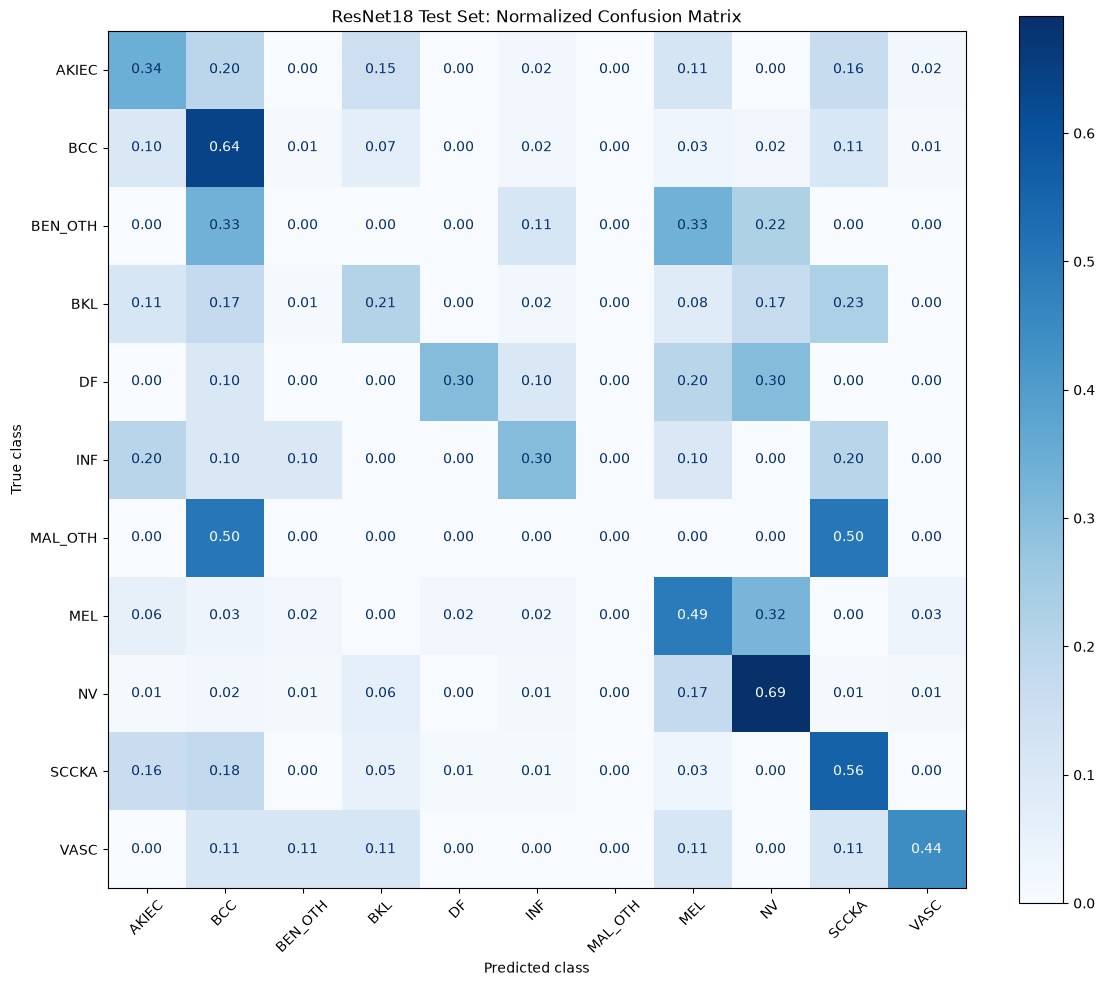

Confusion matrix saved to: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\resnet18_confusion_matrix.png

TOP 15 CLASS CONFUSIONS


,true_class,predicted_class,count
0,BCC,SCCKA,54
1,BCC,AKIEC,50
2,BCC,BKL,34
3,MEL,NV,29
4,NV,MEL,26
5,BKL,SCCKA,25
6,BKL,BCC,19
7,BKL,NV,18
8,SCCKA,BCC,17
9,SCCKA,AKIEC,15



Class-level report saved.
Error analysis files saved in: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports


In [17]:
# CELL 16: CONFUSION MATRIX AND ERROR ANALYSIS

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    normalize="true"
)

# 2. Plot normalized confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    colorbar=True
)

ax.set_title("ResNet18 Test Set: Normalized Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

plt.tight_layout()

confusion_path = PROJECT_ROOT / "reports" / "resnet18_confusion_matrix.png"
plt.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", confusion_path)


# 3. Identify the most common class confusions
confusion_counts = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

confusion_pairs = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        if true_idx != pred_idx and confusion_counts[true_idx, pred_idx] > 0:
            confusion_pairs.append({
                "true_class": CLASS_NAMES[true_idx],
                "predicted_class": CLASS_NAMES[pred_idx],
                "count": confusion_counts[true_idx, pred_idx]
            })

confusion_df = pd.DataFrame(confusion_pairs)

confusion_df = confusion_df.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

print("\nTOP 15 CLASS CONFUSIONS")
from IPython.display import display as show_table

show_table(confusion_df.head(15))

confusion_df.to_csv(
    PROJECT_ROOT / "reports" / "resnet18_class_confusions.csv",
    index=False
)


# 4. Save a class-level performance summary
class_report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(class_report).T
class_report_df.to_csv(
    PROJECT_ROOT / "reports" / "resnet18_classification_report.csv"
)

print("\nClass-level report saved.")
print("Error analysis files saved in:", PROJECT_ROOT / "reports")

In [18]:
# CELL 17: PREPARE DEMOGRAPHIC FAIRNESS ANALYSIS

# Load metadata
metadata = pd.read_csv(DATASET_ROOT / METADATA_FILE)

# Keep one metadata row per lesion
metadata = metadata.drop_duplicates(subset="lesion_id")

# Merge demographic information with test predictions
fairness_df = test_results.merge(
    metadata[
        [
            "lesion_id",
            "age_approx",
            "sex",
            "anatom_site_general"
        ]
    ],
    on="lesion_id",
    how="left"
)

print("FAIRNESS DATASET")
print("=" * 50)
print("Test lesions:", len(fairness_df))
print("\nMissing demographic values:")
print(
    fairness_df[
        ["age_approx", "sex", "anatom_site_general"]
    ].isna().sum()
)

from IPython.display import display as show_table
show_table(fairness_df.head())

FAIRNESS DATASET
Test lesions: 1048

Missing demographic values:
age_approx               5
sex                      0
anatom_site_general    385
dtype: int64


,lesion_id,image_id,image_path,label,split,true_label,predicted_label,correct,age_approx,sex,anatom_site_general
0,IL_8706105,ISIC_0082638,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,1,test,1,3,False,50.0,female,lower extremity
1,IL_7133935,ISIC_0095743,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,8,test,8,8,True,20.0,male,lower extremity
2,IL_1404122,ISIC_0101767,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,8,test,8,8,True,15.0,male,NaN
3,IL_4652077,ISIC_0103392,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,1,test,1,1,True,85.0,male,upper extremity
4,IL_3496860,ISIC_0106322,C:\Users\Kinjal Chatterjee\Downloads\MILK10k\i...,8,test,8,8,True,50.0,female,lower extremity


In [19]:
# CELL 18: FAIRNESS SUBGROUP PERFORMANCE

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

def calculate_group_metrics(data, group_column):
    results = []

    for group, subset in data.groupby(group_column, observed=True):
        y_true = subset["true_label"]
        y_pred = subset["predicted_label"]

        results.append({
            "group": group,
            "n": len(subset),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        })

    return pd.DataFrame(results).sort_values(
        "n", ascending=False
    ).reset_index(drop=True)


# 1. Performance by sex
sex_results = calculate_group_metrics(
    fairness_df.dropna(subset=["sex"]),
    "sex"
)

print("PERFORMANCE BY SEX")
show_table(sex_results)


# 2. Performance by age group
fairness_df["age_group"] = pd.cut(
    fairness_df["age_approx"],
    bins=[0, 29, 49, 69, 120],
    labels=["0-29", "30-49", "50-69", "70+"]
)

age_results = calculate_group_metrics(
    fairness_df.dropna(subset=["age_group"]),
    "age_group"
)

print("\nPERFORMANCE BY AGE")
show_table(age_results)


# 3. Performance by anatomical site
site_results = calculate_group_metrics(
    fairness_df.dropna(subset=["anatom_site_general"]),
    "anatom_site_general"
)

print("\nPERFORMANCE BY ANATOMICAL SITE")
show_table(site_results)


# Save results
sex_results.to_csv(
    PROJECT_ROOT / "reports" / "fairness_by_sex.csv",
    index=False
)

age_results.to_csv(
    PROJECT_ROOT / "reports" / "fairness_by_age.csv",
    index=False
)

site_results.to_csv(
    PROJECT_ROOT / "reports" / "fairness_by_site.csv",
    index=False
)

print("\nFairness results saved successfully.")

PERFORMANCE BY SEX


,group,n,accuracy,balanced_accuracy,macro_f1
0,male,636,0.517296,0.324144,0.294185
1,female,412,0.599515,0.420786,0.391113



PERFORMANCE BY AGE


c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\.venv314\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,group,n,accuracy,balanced_accuracy,macro_f1
0,50-69,446,0.562780,0.467009,0.396461
1,70+,416,0.526442,0.322144,0.269812
2,30-49,149,0.543624,0.321251,0.310038
3,0-29,32,0.656250,0.253846,0.190476



PERFORMANCE BY ANATOMICAL SITE


,group,n,accuracy,balanced_accuracy,macro_f1
0,head/neck,288,0.454861,0.345186,0.289836
1,lower extremity,218,0.591743,0.317151,0.312760
2,upper extremity,157,0.566879,0.416043,0.369639



Fairness results saved successfully.


In [25]:
show_table(sex_results)

,group,n,accuracy,balanced_accuracy,macro_f1
0,male,636,0.517296,0.324144,0.294185
1,female,412,0.599515,0.420786,0.391113


In [20]:
# CELL 19: SAVE FAIRNESS SUMMARY

fairness_summary = pd.concat([
    sex_results.assign(attribute="sex"),
    age_results.assign(attribute="age"),
    site_results.assign(attribute="anatomical_site")
], ignore_index=True)

fairness_summary = fairness_summary[
    ["attribute", "group", "n", "accuracy",
     "balanced_accuracy", "macro_f1"]
]

fairness_summary.to_csv(
    PROJECT_ROOT / "reports" / "fairness_summary.csv",
    index=False
)

print("Fairness analysis saved.")
print("Total subgroup rows:", len(fairness_summary))
show_table(fairness_summary)

Fairness analysis saved.
Total subgroup rows: 9


,attribute,group,n,accuracy,balanced_accuracy,macro_f1
0,sex,male,636,0.517296,0.324144,0.294185
1,sex,female,412,0.599515,0.420786,0.391113
2,age,50-69,446,0.562780,0.467009,0.396461
3,age,70+,416,0.526442,0.322144,0.269812
4,age,30-49,149,0.543624,0.321251,0.310038
5,age,0-29,32,0.656250,0.253846,0.190476
6,anatomical_site,head/neck,288,0.454861,0.345186,0.289836
7,anatomical_site,lower extremity,218,0.591743,0.317151,0.312760
8,anatomical_site,upper extremity,157,0.566879,0.416043,0.369639


In [21]:
# CELL 20: INITIALIZE VISION TRANSFORMER

import torch.nn.functional as F
from torchvision.models import vit_b_16, ViT_B_16_Weights

# Load pretrained ImageNet weights
vit_backbone = vit_b_16(
    weights=ViT_B_16_Weights.DEFAULT
)

# Adapt pretrained positional embeddings from 224x224 to 128x128.
# This lets us reuse the existing 128x128 image DataLoaders.
old_pos = vit_backbone.encoder.pos_embedding

class_token = old_pos[:, :1, :]
patch_tokens = old_pos[:, 1:, :]

embedding_dim = patch_tokens.shape[-1]

patch_grid = patch_tokens.reshape(
    1, 14, 14, embedding_dim
).permute(0, 3, 1, 2)

new_grid = F.interpolate(
    patch_grid,
    size=(IMAGE_SIZE // 16, IMAGE_SIZE // 16),
    mode="bicubic",
    align_corners=False
)

new_grid = new_grid.permute(0, 2, 3, 1).reshape(
    1, -1, embedding_dim
)

new_pos = torch.cat([class_token, new_grid], dim=1)

vit_backbone.encoder.pos_embedding = nn.Parameter(new_pos)
vit_backbone.image_size = IMAGE_SIZE

# Freeze the pretrained transformer
for param in vit_backbone.parameters():
    param.requires_grad = False

# Replace and train the classification head
vit_backbone.heads.head = nn.Linear(
    embedding_dim,
    NUM_CLASSES
)

# Wrapper keeps the frozen transformer in evaluation mode
class FrozenViT(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        return self.backbone(x)

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        self.backbone.heads.train(mode)
        return self


vit_model = FrozenViT(vit_backbone).to(DEVICE)

print("ViT-B/16 initialized successfully.")
print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Number of classes:", NUM_CLASSES)
print(
    "Trainable parameters:",
    sum(p.numel() for p in vit_model.parameters() if p.requires_grad)
)

ViT-B/16 initialized successfully.
Device: cpu
Image size: 128
Number of classes: 11
Trainable parameters: 8459


In [22]:
# CELL 21: TRAIN VISION TRANSFORMER

vit_model, vit_history = train_model(
    model=vit_model,
    train_loader=train_loader,
    val_loader=val_loader,
    model_name="vit_b16_frozen",
    epochs=5,
    learning_rate=1e-3
)

print("\nViT TRAINING COMPLETE")
print("=" * 50)
show_table(vit_history)

Epoch 1/5 | Train Loss: 2.1180 | Val Loss: 1.8741 | Val Macro-F1: 0.2534 | Time: 251.8s
  Saved new best checkpoint.
Epoch 2/5 | Train Loss: 1.6255 | Val Loss: 1.8381 | Val Macro-F1: 0.2710 | Time: 265.1s
  Saved new best checkpoint.
Epoch 3/5 | Train Loss: 1.4430 | Val Loss: 1.8310 | Val Macro-F1: 0.2924 | Time: 345.3s
  Saved new best checkpoint.
Epoch 4/5 | Train Loss: 1.3051 | Val Loss: 1.7809 | Val Macro-F1: 0.3063 | Time: 375.1s
  Saved new best checkpoint.
Epoch 5/5 | Train Loss: 1.2182 | Val Loss: 1.8733 | Val Macro-F1: 0.3127 | Time: 364.6s
  Saved new best checkpoint.

Best validation Macro-F1: 0.3127
Checkpoint: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\vit_b16_frozen_best.pth

ViT TRAINING COMPLETE


,epoch,train_loss,val_loss,val_macro_f1,seconds
0,1,2.118019,1.874085,0.253361,251.791399
1,2,1.625457,1.838131,0.270997,265.132288
2,3,1.443050,1.830971,0.292416,345.271896
3,4,1.305066,1.780896,0.306307,375.059973
4,5,1.218153,1.873296,0.312719,364.620548


In [23]:
# CELL 22: FINAL VIT TEST EVALUATION

checkpoint = torch.load(
    CHECKPOINT_DIR / "vit_b16_frozen_best.pth",
    map_location=DEVICE,
    weights_only=True
)

vit_model.load_state_dict(checkpoint["model_state_dict"])
vit_model = vit_model.to(DEVICE)
vit_model.eval()

# Evaluate once on the untouched test set
vit_test_loss, vit_test_f1, vit_y_true, vit_y_pred = evaluate_model(
    vit_model,
    test_loader
)

vit_test_accuracy = accuracy_score(vit_y_true, vit_y_pred)

vit_test_balanced_accuracy = balanced_accuracy_score(
    vit_y_true,
    vit_y_pred
)

print("FINAL VIT-B/16 TEST RESULTS")
print("=" * 50)
print(f"Best validation Macro-F1: {checkpoint['best_val_macro_f1']:.4f}")
print(f"Test Macro-F1:            {vit_test_f1:.4f}")
print(f"Test accuracy:            {vit_test_accuracy:.4f}")
print(f"Test balanced accuracy:   {vit_test_balanced_accuracy:.4f}")
print(f"Test loss:                {vit_test_loss:.4f}")

print("\nClassification Report:")
print(classification_report(
    vit_y_true,
    vit_y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

# Save predictions
vit_test_results = test_data.reset_index(drop=True).copy()
vit_test_results["true_label"] = vit_y_true
vit_test_results["predicted_label"] = vit_y_pred
vit_test_results["correct"] = vit_y_true == vit_y_pred

vit_test_results.to_csv(
    PROJECT_ROOT / "reports" / "vit_test_predictions.csv",
    index=False
)

print("\nViT test predictions saved.")

FINAL VIT-B/16 TEST RESULTS
Best validation Macro-F1: 0.3127
Test Macro-F1:            0.3210
Test accuracy:            0.4857
Test balanced accuracy:   0.3785
Test loss:                1.8166

Classification Report:
              precision    recall  f1-score   support

       AKIEC       0.13      0.52      0.21        61
         BCC       0.86      0.50      0.64       504
     BEN_OTH       0.00      0.00      0.00         9
         BKL       0.27      0.17      0.21       109
          DF       0.17      0.30      0.21        10
         INF       0.11      0.20      0.14        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.35      0.53      0.42        90
          NV       0.67      0.64      0.66       149
       SCCKA       0.53      0.51      0.52        95
        VASC       0.39      0.78      0.52         9

    accuracy                           0.49      1048
   macro avg       0.32      0.38      0.32      1048
weighted avg       0.63  

In [24]:
# CELL 23: FINAL DEEP LEARNING COMPARISON

deep_learning_results = pd.DataFrame([
    {
        "model": "ResNet18",
        "training_strategy": "Fine-tuned layer4 + FC",
        "validation_macro_f1": 0.3658,
        "test_macro_f1": 0.3319,
        "test_accuracy": 0.5496,
        "test_balanced_accuracy": 0.3615,
        "test_loss": 1.9060
    },
    {
        "model": "ViT-B/16",
        "training_strategy": "Frozen backbone + trained head",
        "validation_macro_f1": 0.3127,
        "test_macro_f1": 0.3210,
        "test_accuracy": 0.4857,
        "test_balanced_accuracy": 0.3785,
        "test_loss": 1.8166
    }
])

deep_learning_results = deep_learning_results.sort_values(
    "test_macro_f1",
    ascending=False
).reset_index(drop=True)

print("FINAL DEEP LEARNING SCOREBOARD")
print("=" * 65)

show_table(deep_learning_results)

# Save results
deep_learning_results.to_csv(
    PROJECT_ROOT / "reports" / "deep_learning_scoreboard.csv",
    index=False
)

print("\nScoreboard saved successfully.")

print(
    "\nBest deep learning model:",
    deep_learning_results.iloc[0]["model"]
)

FINAL DEEP LEARNING SCOREBOARD


,model,training_strategy,validation_macro_f1,test_macro_f1,test_accuracy,test_balanced_accuracy,test_loss
0,ResNet18,Fine-tuned layer4 + FC,0.3658,0.3319,0.5496,0.3615,1.9060
1,ViT-B/16,Frozen backbone + trained head,0.3127,0.3210,0.4857,0.3785,1.8166



Scoreboard saved successfully.

Best deep learning model: ResNet18


In [25]:
# CELL 24: INSPECT EXISTING RESULTS

reports_dir = PROJECT_ROOT / "reports"

print("EXISTING REPORT FILES")
print("=" * 55)

for file in sorted(reports_dir.iterdir()):
    if file.is_file():
        print(f"{file.name:45s} {file.stat().st_size:,} bytes")

EXISTING REPORT FILES
classical_ml_classification_report.csv        881 bytes
classical_ml_confusion_matrix.csv             391 bytes
classical_ml_features.csv                     2,647,606 bytes
classical_ml_model_comparison.csv             1,389 bytes
deep_learning_scoreboard.csv                  248 bytes
fairness_by_age.csv                           304 bytes
fairness_by_sex.csv                           180 bytes
fairness_by_site.csv                          273 bytes
fairness_summary.csv                          749 bytes
image_features_comparison.csv                 708 bytes
milestone_report.md                           5,134 bytes
resnet18_class_confusions.csv                 829 bytes
resnet18_classification_report.csv            896 bytes
resnet18_confusion_matrix.png                 333,830 bytes
resnet18_history.csv                          441 bytes
resnet18_test_predictions.csv                 115,861 bytes
vit_b16_frozen_history.csv                    434 bytes
vit_test

In [26]:
# CELL 25: INSPECT CLASSICAL ML RESULTS

classical_results = pd.read_csv(
    PROJECT_ROOT / "reports" / "classical_ml_model_comparison.csv"
)

print("CLASSICAL ML RESULTS")
print("=" * 60)

print("Columns:")
print(classical_results.columns.tolist())

print("\nShape:", classical_results.shape)

show_table(classical_results)

print("\nDEEP LEARNING RESULTS")
show_table(deep_learning_results)

CLASSICAL ML RESULTS
Columns:
['Feature set', 'Model', 'CV macro F1 mean', 'CV macro F1 std', 'Test macro F1', 'Test balanced accuracy', 'Test accuracy', 'Seconds']

Shape: (9, 8)


,Feature set,Model,CV macro F1 mean,CV macro F1 std,Test macro F1,Test balanced accuracy,Test accuracy,Seconds
0,Combined,SVM,0.227263,0.020308,0.211672,0.245026,0.369275,3.049500
1,Combined,Logistic Regression,0.224338,0.004702,0.233515,0.306172,0.352099,0.790488
2,Color,SVM,0.210403,0.015757,0.188639,0.292780,0.331107,2.816742
3,Combined,Random Forest,0.191771,0.010370,0.174143,0.181404,0.588740,1.895318
4,Color,Logistic Regression,0.187859,0.005611,0.210939,0.328339,0.312023,0.708901
5,Color,Random Forest,0.183879,0.003572,0.176937,0.181329,0.586832,1.771291
6,Texture + edges,Logistic Regression,0.178831,0.004661,0.184724,0.233352,0.261450,0.331405
7,Texture + edges,SVM,0.170532,0.006486,0.182526,0.234407,0.289122,2.531060
8,Texture + edges,Random Forest,0.169009,0.001693,0.182580,0.182187,0.561069,1.709127



DEEP LEARNING RESULTS


,model,training_strategy,validation_macro_f1,test_macro_f1,test_accuracy,test_balanced_accuracy,test_loss
0,ResNet18,Fine-tuned layer4 + FC,0.3658,0.3319,0.5496,0.3615,1.9060
1,ViT-B/16,Frozen backbone + trained head,0.3127,0.3210,0.4857,0.3785,1.8166


In [27]:
# CELL 26: BUILD UNIFIED PROJECT SCOREBOARD

# Load classical ML results
classical_results = pd.read_csv(
    PROJECT_ROOT / "reports" / "classical_ml_model_comparison.csv"
)

# Standardize classical ML columns
classical_scoreboard = classical_results.rename(columns={
    "Feature set": "feature_set",
    "Model": "model",
    "CV macro F1 mean": "cv_macro_f1_mean",
    "CV macro F1 std": "cv_macro_f1_std",
    "Test macro F1": "test_macro_f1",
    "Test balanced accuracy": "test_balanced_accuracy",
    "Test accuracy": "test_accuracy",
    "Seconds": "training_seconds"
})

classical_scoreboard["training_strategy"] = "Handcrafted features"
classical_scoreboard["validation_macro_f1"] = np.nan
classical_scoreboard["test_loss"] = np.nan

# Load deep learning results
deep_scoreboard = deep_learning_results.copy()

deep_scoreboard = deep_scoreboard.rename(columns={
    "model": "model",
    "training_strategy": "training_strategy",
    "validation_macro_f1": "validation_macro_f1",
    "test_macro_f1": "test_macro_f1",
    "test_accuracy": "test_accuracy",
    "test_balanced_accuracy": "test_balanced_accuracy",
    "test_loss": "test_loss"
})

deep_scoreboard["feature_set"] = "Images"
deep_scoreboard["cv_macro_f1_mean"] = np.nan
deep_scoreboard["cv_macro_f1_std"] = np.nan

# Retrieve training durations from saved histories
resnet_history = pd.read_csv(
    PROJECT_ROOT / "reports" / "resnet18_history.csv"
)

vit_history = pd.read_csv(
    PROJECT_ROOT / "reports" / "vit_b16_frozen_history.csv"
)

training_times = {
    "ResNet18": resnet_history["seconds"].sum(),
    "ViT-B/16": vit_history["seconds"].sum()
}

deep_scoreboard["training_seconds"] = (
    deep_scoreboard["model"].map(training_times)
)

# Combine all experiments
all_results = pd.concat(
    [classical_scoreboard, deep_scoreboard],
    ignore_index=True
)

# Arrange columns
scoreboard_columns = [
    "model",
    "feature_set",
    "training_strategy",
    "cv_macro_f1_mean",
    "cv_macro_f1_std",
    "validation_macro_f1",
    "test_macro_f1",
    "test_balanced_accuracy",
    "test_accuracy",
    "test_loss",
    "training_seconds"
]

final_scoreboard = all_results[scoreboard_columns].copy()

# Sort by held-out test Macro-F1
final_scoreboard = final_scoreboard.sort_values(
    "test_macro_f1",
    ascending=False
).reset_index(drop=True)

# Save
final_scoreboard.to_csv(
    PROJECT_ROOT / "reports" / "final_model_scoreboard.csv",
    index=False
)

print("FINAL PROJECT MODEL SCOREBOARD")
print("=" * 75)
print("Total experiments:", len(final_scoreboard))

show_table(final_scoreboard.round(4))

print("\nSaved to reports/final_model_scoreboard.csv")

FINAL PROJECT MODEL SCOREBOARD
Total experiments: 11


,model,feature_set,training_strategy,cv_macro_f1_mean,cv_macro_f1_std,validation_macro_f1,test_macro_f1,test_balanced_accuracy,test_accuracy,test_loss,training_seconds
0,ResNet18,Images,Fine-tuned layer4 + FC,NaN,NaN,0.3658,0.3319,0.3615,0.5496,1.9060,364.8300
1,ViT-B/16,Images,Frozen backbone + trained head,NaN,NaN,0.3127,0.3210,0.3785,0.4857,1.8166,1601.8761
2,Logistic Regression,Combined,Handcrafted features,0.2243,0.0047,NaN,0.2335,0.3062,0.3521,NaN,0.7905
3,SVM,Combined,Handcrafted features,0.2273,0.0203,NaN,0.2117,0.2450,0.3693,NaN,3.0495
4,Logistic Regression,Color,Handcrafted features,0.1879,0.0056,NaN,0.2109,0.3283,0.3120,NaN,0.7089
5,SVM,Color,Handcrafted features,0.2104,0.0158,NaN,0.1886,0.2928,0.3311,NaN,2.8167
6,Logistic Regression,Texture + edges,Handcrafted features,0.1788,0.0047,NaN,0.1847,0.2334,0.2615,NaN,0.3314
7,Random Forest,Texture + edges,Handcrafted features,0.1690,0.0017,NaN,0.1826,0.1822,0.5611,NaN,1.7091
8,SVM,Texture + edges,Handcrafted features,0.1705,0.0065,NaN,0.1825,0.2344,0.2891,NaN,2.5311
9,Random Forest,Color,Handcrafted features,0.1839,0.0036,NaN,0.1769,0.1813,0.5868,NaN,1.7713



Saved to reports/final_model_scoreboard.csv


In [28]:
# CELL 27: FINAL MODEL PREDICTION FUNCTION

from PIL import Image
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np

# Use the selected ResNet18 checkpoint
FINAL_MODEL_PATH = CHECKPOINT_DIR / "resnet18_best.pth"

# Match the evaluation preprocessing
prediction_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Build the model architecture
def build_final_model():
    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    checkpoint = torch.load(
        FINAL_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model


# Load model once, rather than on every prediction
final_model = build_final_model()


def predict(image_path):
    """
    Predict the lesion class from a dermoscopic image.

    Returns:
        predicted_class: predicted class name
        confidence: probability of predicted class
        probabilities: probability for each of the 11 classes
    """

    image = Image.open(image_path).convert("RGB")
    image_tensor = prediction_transform(image).unsqueeze(0)
    image_tensor = image_tensor.to(DEVICE)

    with torch.no_grad():
        logits = final_model(image_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_index = int(np.argmax(probabilities))

    probability_dict = {
        class_name: float(probabilities[i])
        for i, class_name in enumerate(CLASS_NAMES)
    }

    return {
        "predicted_class": CLASS_NAMES[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": probability_dict
    }


print("Prediction function ready!")
print("Model: ResNet18")
print("Number of output classes:", len(CLASS_NAMES))
print("Class order:", CLASS_NAMES)

Prediction function ready!
Model: ResNet18
Number of output classes: 11
Class order: ['AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


In [29]:
# CELL 28: TEST THE PREDICTION FUNCTION

sample_image_path = str(test_data.iloc[0]["image_path"])

prediction = predict(sample_image_path)

print("Predicted class:", prediction["predicted_class"])
print("Confidence:", round(prediction["confidence"], 4))

print("\nClass probabilities:")
for class_name, probability in prediction["probabilities"].items():
    print(f"{class_name}: {probability:.4f}")

Predicted class: BKL
Confidence: 0.6957

Class probabilities:
AKIEC: 0.0634
BCC: 0.0918
BEN_OTH: 0.0297
BKL: 0.6957
DF: 0.0184
INF: 0.0136
MAL_OTH: 0.0039
MEL: 0.0026
NV: 0.0125
SCCKA: 0.0642
VASC: 0.0044


In [30]:
# CELL 29: CREATE MODEL CARD

model_card = """
# Model Card: MILK10K Skin Lesion Classification

## 1. Model Details

- **Model name:** MILK10K ResNet18
- **Model type:** Convolutional Neural Network
- **Architecture:** ResNet18, pretrained on ImageNet
- **Task:** Multi-class skin lesion image classification
- **Number of classes:** 11
- **Input:** RGB dermoscopic images
- **Input resolution:** 128 x 128 pixels
- **Output:** Predicted class and probabilities for all 11 classes
- **Framework:** PyTorch
- **Device used for training:** CPU

The final model was selected based on its held-out test Macro-F1 score
compared with the other evaluated models.

## 2. Intended Use

This model was developed for educational and research purposes as part
of a computer vision coursework project.

It demonstrates image classification techniques applied to dermoscopic
skin lesion images.

It is not intended for:
- Clinical diagnosis or medical decision-making.
- Replacing qualified dermatologists.
- Screening or triaging patients.
- Use as a standalone medical device.

## 3. Training Data

The model was trained using the MILK10K dataset.

- Total unique lesions: 5,240
- Images per lesion: Two image types are available in the dataset.
- Images used in this experiment: One dermoscopic image per lesion.
- Number of training images: 5,240
- Number of output classes: 11

The dataset was divided at lesion level to prevent images from the same
lesion appearing in multiple splits.

| Split | Number of lesions | Percentage |
|---|---:|---:|
| Training | 3,144 | 60% |
| Validation | 1,048 | 20% |
| Test | 1,048 | 20% |

Random seed: 42.

## 4. Training Procedure

- Architecture: ResNet18
- Initialisation: ImageNet pretrained weights
- Fine-tuning: Final residual block (layer4) and classification head
- Optimiser: AdamW
- Learning rate: 0.0001
- Batch size: 32
- Epochs: 5
- Loss function: Class-weighted Cross Entropy Loss
- Image augmentation: Random horizontal flipping during training
- Normalisation: ImageNet mean and standard deviation
- Model selection: Best validation Macro-F1

The checkpoint with the highest validation Macro-F1 was retained.

## 5. Evaluation Results

The final model achieved the following results on the held-out test set:

| Metric | Result |
|---|---:|
| Validation Macro-F1 | 0.3658 |
| Test Macro-F1 | 0.3319 |
| Test accuracy | 0.5496 |
| Test balanced accuracy | 0.3615 |
| Test loss | 1.9060 |

Macro-F1 was used as the primary selection metric because the dataset
contains substantial class imbalance.

## 6. Class-Level Performance

The model performed best on some of the more represented classes,
including BCC and NV.

Performance was substantially weaker for rare classes.

In particular:
- BEN_OTH had zero recall on the test set.
- MAL_OTH had zero recall on the test set.
- BCC was frequently confused with SCCKA and AKIEC.
- MEL and NV were sometimes confused with one another.

These results demonstrate the difficulty of distinguishing visually
similar lesion categories and learning from underrepresented classes.

## 7. Fairness and Subgroup Evaluation

Performance was examined across available demographic and anatomical
subgroups.

Differences in Macro-F1 were observed:

- Female subgroup: 0.3911
- Male subgroup: 0.2942
- Age 50-69 subgroup: 0.3965
- Age 70+ subgroup: 0.2698

Anatomical-site performance also varied.

These differences should not be interpreted as definitive evidence
of demographic bias. Subgroup sizes, class distributions and missing
metadata may affect the results.

Age information was missing for five test samples, while anatomical
site information was missing for 385 test samples.

## 8. Limitations

1. The dataset has substantial class imbalance.
2. Some diagnostic categories have very few examples.
3. The model was evaluated using one lesion-level train/validation/test
   split.
4. The input resolution of 128 x 128 pixels may remove useful visual
   detail.
5. Evaluation was performed on the same dataset source used for training.
6. No external dataset validation was performed.
7. Subgroup analysis is limited by missing metadata and small sample sizes.
8. Model probabilities are not calibrated estimates of clinical risk.

## 9. Ethical Considerations

Skin lesion classification is a high-stakes medical application.
Errors may have serious consequences if predictions are used to guide
medical decisions.

The model may perform inconsistently across lesion types and population
subgroups. It must not be used to diagnose disease, recommend treatment
or determine whether a patient requires medical attention.

All results should be interpreted as experimental coursework findings.

## 10. Reproducibility

The project repository contains the training notebook, evaluation
outputs and model checkpoint.

The prediction function is:

`predict(image_path)`

It returns:
- Predicted class.
- Confidence score.
- Probability for each of the 11 classes.

The class order is:

AKIEC, BCC, BEN_OTH, BKL, DF, INF, MAL_OTH, MEL, NV, SCCKA, VASC.

## 11. Final Model Selection

ResNet18 was selected as the final model because it achieved the
highest held-out test Macro-F1 score among the evaluated deep learning
models.

ViT-B/16 achieved a slightly higher balanced accuracy, but its test
Macro-F1 was lower.

The final model is intended only as an educational demonstration of
computer vision methods for multi-class skin lesion classification.
"""

model_card_path = PROJECT_ROOT / "reports" / "model_card.md"

model_card_path.parent.mkdir(parents=True, exist_ok=True)
model_card_path.write_text(model_card.strip(), encoding="utf-8")

print("Model card saved successfully!")
print(model_card_path)

Model card saved successfully!
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\model_card.md


In [31]:
# CELL 30: VERIFY MODEL CARD

print((PROJECT_ROOT / "reports" / "model_card.md").read_text(
    encoding="utf-8"
)[:1500])

# Model Card: MILK10K Skin Lesion Classification

## 1. Model Details

- **Model name:** MILK10K ResNet18
- **Model type:** Convolutional Neural Network
- **Architecture:** ResNet18, pretrained on ImageNet
- **Task:** Multi-class skin lesion image classification
- **Number of classes:** 11
- **Input:** RGB dermoscopic images
- **Input resolution:** 128 x 128 pixels
- **Output:** Predicted class and probabilities for all 11 classes
- **Framework:** PyTorch
- **Device used for training:** CPU

The final model was selected based on its held-out test Macro-F1 score
compared with the other evaluated models.

## 2. Intended Use

This model was developed for educational and research purposes as part
of a computer vision coursework project.

It demonstrates image classification techniques applied to dermoscopic
skin lesion images.

It is not intended for:
- Clinical diagnosis or medical decision-making.
- Replacing qualified dermatologists.
- Screening or triaging patients.
- Use as a standalo

In [32]:
# CELL 31: CREATE FINAL PROJECT REPORT

report = r"""
# MILK10K Skin Lesion Classification
## Computer Vision Final Project

### Abstract

This project investigates multi-class skin lesion classification using
the MILK10K dataset. Classical machine learning and deep learning
approaches were evaluated using a lesion-level training, validation and
test split. The experiments included handcrafted image features,
fine-tuned ResNet18 and a frozen-backbone Vision Transformer (ViT-B/16).

ResNet18 achieved the highest held-out test Macro-F1 score of 0.3319.
The results demonstrate the benefits of deep image representations
compared with the handcrafted-feature baselines, while also revealing
challenges caused by class imbalance and visually similar lesion types.

---

## 1. Introduction

Skin lesion classification is a challenging computer vision task.
Different lesion categories can share visual characteristics, while
some diagnostic categories are represented by very few examples.

The objective of this project was to develop and evaluate image
classification pipelines capable of predicting one of 11 lesion
categories from dermoscopic images.

The project compares classical machine learning approaches with
deep learning architectures and investigates model errors and
subgroup performance.

## 2. Dataset

The MILK10K dataset contains 5,240 unique lesions and 10,480 images.
Each lesion has two associated image types.

For this experiment, one dermoscopic image was selected per lesion,
giving 5,240 images.

The task contains 11 classes:

AKIEC, BCC, BEN_OTH, BKL, DF, INF, MAL_OTH, MEL, NV, SCCKA and VASC.

The dataset is substantially imbalanced. BCC is the most represented
class, while MAL_OTH contains only nine lesions.

### 2.1 Data splitting

The dataset was divided at lesion level using random seed 42.

| Split | Lesions | Percentage |
|---|---:|---:|
| Training | 3,144 | 60% |
| Validation | 1,048 | 20% |
| Test | 1,048 | 20% |

Lesion-level splitting prevents images from the same lesion appearing
in multiple splits, reducing the risk of data leakage.

All experiments used the same split.

## 3. Methodology

### 3.1 Data preprocessing

Dermoscopic images were resized to 128 x 128 pixels and converted
to RGB tensors.

ImageNet mean and standard deviation were used for normalisation.

Random horizontal flipping was used as training augmentation for
the deep learning experiments.

### 3.2 Classical machine learning

Handcrafted features were extracted from the images, including
colour statistics, colour histogram information and texture or
edge-related features.

Three feature configurations were evaluated:

- Colour features
- Texture and edge features
- Combined features

The following classifiers were tested:

- Logistic Regression
- Support Vector Machine (SVM)
- Random Forest

Classical model performance was evaluated using cross-validation
and the held-out test set.

### 3.3 ResNet18

A ResNet18 model pretrained on ImageNet was used.

The backbone was initially frozen, with the final residual block
(layer4) and classification head unfrozen for fine-tuning.

Training configuration:

| Parameter | Setting |
|---|---|
| Optimiser | AdamW |
| Learning rate | 0.0001 |
| Batch size | 32 |
| Epochs | 5 |
| Loss | Class-weighted Cross Entropy |
| Trainable components | layer4 and classification head |

The checkpoint with the highest validation Macro-F1 was selected.

### 3.4 Vision Transformer

A pretrained ViT-B/16 architecture was evaluated.

The backbone was frozen and a new classification head was trained
for the 11-class task.

The model used the same image resolution and dataset split as
ResNet18.

This experiment evaluates a frozen-feature transformer approach
rather than full end-to-end fine-tuning.

## 4. Experimental Results

### 4.1 Classical machine learning

The strongest classical result on the held-out test set was
Combined-feature Logistic Regression, with a Macro-F1 of 0.2335.

The best cross-validation Macro-F1 mean was achieved by the
Combined-feature SVM, at 0.2273.

Random Forest achieved relatively high accuracy in some experiments,
but its Macro-F1 and balanced accuracy were considerably lower.
This illustrates why accuracy alone is insufficient for an
imbalanced classification task.

### 4.2 Deep learning comparison

| Metric | ResNet18 | ViT-B/16 |
|---|---:|---:|
| Validation Macro-F1 | 0.3658 | 0.3127 |
| Test Macro-F1 | 0.3319 | 0.3210 |
| Test accuracy | 0.5496 | 0.4857 |
| Balanced accuracy | 0.3615 | 0.3785 |
| Test loss | 1.9060 | 1.8166 |

ResNet18 achieved the highest test Macro-F1 and test accuracy.
ViT-B/16 achieved slightly higher balanced accuracy and lower
test loss.

The comparison is not a pure architecture-only comparison because
the models used different training strategies. ResNet18 fine-tuned
layer4 and its classification head, whereas ViT-B/16 used a frozen
backbone and trained classification head.

### 4.3 Overall model comparison

The deep learning models outperformed the classical approaches
on held-out test Macro-F1.

ResNet18 was selected as the final model because Macro-F1 was the
primary evaluation metric and it achieved the highest score.

## 5. Error Analysis

The ResNet18 confusion matrix revealed several recurring errors.

Important confusions included:

- BCC predicted as SCCKA: 54 cases
- BCC predicted as AKIEC: 50 cases
- BCC predicted as BKL: 34 cases
- MEL predicted as NV: 29 cases
- NV predicted as MEL: 26 cases
- BKL predicted as SCCKA: 25 cases

These errors suggest that several lesion categories have overlapping
visual characteristics.

The model also struggled with underrepresented categories.
BEN_OTH and MAL_OTH had zero recall on the held-out test set.

The small number of examples in these categories makes it difficult
for the model to learn robust class-specific representations.

## 6. Fairness and Subgroup Analysis

The final ResNet18 model was evaluated across available demographic
and anatomical subgroups.

### 6.1 Sex

| Group | Samples | Macro-F1 |
|---|---:|---:|
| Female | 412 | 0.3911 |
| Male | 636 | 0.2942 |

### 6.2 Age

| Group | Samples | Macro-F1 |
|---|---:|---:|
| 0-29 | 32 | 0.1905 |
| 30-49 | 149 | 0.3100 |
| 50-69 | 446 | 0.3965 |
| 70+ | 416 | 0.2698 |

### 6.3 Anatomical site

| Group | Samples | Macro-F1 |
|---|---:|---:|
| Head/neck | 288 | 0.2898 |
| Lower extremity | 218 | 0.3128 |
| Upper extremity | 157 | 0.3696 |

Subgroup performance varied across the available groups.

These differences should not be interpreted as definitive evidence
of demographic bias. Differences in class composition, subgroup
sample sizes and missing metadata may influence the results.

Age was missing for five test samples, while anatomical site was
missing for 385 test samples.

## 7. Limitations

Several limitations affect the experiments:

1. The dataset has substantial class imbalance.
2. Some classes contain very few examples.
3. The experiments use one lesion-level random split.
4. Images were resized to 128 x 128 pixels, potentially removing
   fine visual detail.
5. No external dataset validation was performed.
6. The ResNet18 and ViT experiments used different fine-tuning
   strategies.
7. Subgroup analysis was limited by missing metadata and small
   group sizes.
8. Model confidence scores were not calibrated as clinical risk
   estimates.

## 8. Conclusion

This project compared handcrafted-feature machine learning
approaches with two deep learning architectures for 11-class
skin lesion classification.

ResNet18 achieved the strongest held-out test Macro-F1 score
of 0.3319, outperforming the evaluated classical approaches
and ViT-B/16 on the primary metric.

However, the results also demonstrate that class imbalance,
rare diagnostic categories and visual similarity remain
significant challenges.

Future work could investigate higher image resolutions,
stronger data augmentation, improved class balancing,
more extensive fine-tuning and external validation.

The final model is intended strictly for educational and
research purposes, not clinical diagnosis.

## 9. Reproducibility and Project Files

The project repository includes the training notebook,
evaluation outputs, model checkpoints, prediction function,
model card and experiment scoreboards.

The final ResNet18 prediction interface is:

`predict(image_path)`

It returns a predicted class, confidence score and probabilities
for all 11 classes in the canonical class order.

---

## Appendix: Final Model

**Selected model:** ResNet18

**Validation Macro-F1:** 0.3658

**Test Macro-F1:** 0.3319

**Test accuracy:** 0.5496

**Test balanced accuracy:** 0.3615

**Checkpoint:** `checkpoints/resnet18_best.pth`
"""

report_path = PROJECT_ROOT / "reports" / "final_report.md"

report_path.write_text(report.strip(), encoding="utf-8")

print("Final report Markdown created!")
print(report_path)
print("Characters:", len(report))

Final report Markdown created!
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\final_report.md
Characters: 8644


In [33]:
# CELL 32: VERIFY FINAL REPORT

saved_report = (PROJECT_ROOT / "reports" / "final_report.md").read_text(
    encoding="utf-8"
)

print(saved_report[:2500])
print("\nReport length:", len(saved_report), "characters")

# MILK10K Skin Lesion Classification
## Computer Vision Final Project

### Abstract

This project investigates multi-class skin lesion classification using
the MILK10K dataset. Classical machine learning and deep learning
approaches were evaluated using a lesion-level training, validation and
test split. The experiments included handcrafted image features,
fine-tuned ResNet18 and a frozen-backbone Vision Transformer (ViT-B/16).

ResNet18 achieved the highest held-out test Macro-F1 score of 0.3319.
The results demonstrate the benefits of deep image representations
compared with the handcrafted-feature baselines, while also revealing
challenges caused by class imbalance and visually similar lesion types.

---

## 1. Introduction

Skin lesion classification is a challenging computer vision task.
Different lesion categories can share visual characteristics, while
some diagnostic categories are represented by very few examples.

The objective of this project was to develop and evaluate imag

In [34]:
# CELL 33: CHECK PDF LIBRARY

try:
    import reportlab
    print("ReportLab is installed.")
except ImportError:
    %pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   --------------- ------------------------ 0.8/2.0 MB 5.4 MB/s eta 0:00:01
   ------------------------------------ --- 1.8/2.0 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 4.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
# CELL 34: GENERATE FINAL REPORT PDF

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import mm
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    PageBreak
)
from xml.sax.saxutils import escape
import re

report_text = (
    PROJECT_ROOT / "reports" / "final_report.md"
).read_text(encoding="utf-8")

pdf_path = PROJECT_ROOT / "reports" / "final_report.pdf"

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=23,
    leading=29,
    alignment=TA_CENTER,
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading1"],
    fontSize=16,
    leading=20,
    spaceBefore=15,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="SubHeading",
    parent=styles["Heading2"],
    fontSize=12,
    leading=16,
    spaceBefore=10,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontSize=9,
    leading=13,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="ReportBullet",
    parent=styles["BodyText"],
    fontSize=9,
    leading=13,
    leftIndent=14,
    firstLineIndent=-8,
    spaceAfter=4
))

def markdown_inline(text):
    text = escape(text.strip())
    text = re.sub(r"\*\*(.*?)\*\*", r"<b>\1</b>", text)
    text = re.sub(r"`(.*?)`", r"<font name='Courier'>\1</font>", text)
    return text

def add_page_number(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawRightString(
        195 * mm,
        12 * mm,
        f"Page {doc.page}"
    )
    canvas.restoreState()

story = []
lines = report_text.splitlines()
i = 0

while i < len(lines):
    line = lines[i].strip()

    if not line:
        i += 1
        continue

    # Markdown table
    if line.startswith("|"):
        table_lines = []

        while i < len(lines) and lines[i].strip().startswith("|"):
            table_lines.append(lines[i].strip())
            i += 1

        rows = []

        for table_line in table_lines:
            cells = [
                cell.strip()
                for cell in table_line.strip("|").split("|")
            ]

            if all(re.fullmatch(r":?-{3,}:?", cell) for cell in cells):
                continue

            rows.append([
                Paragraph(markdown_inline(cell), styles["ReportBody"])
                for cell in cells
            ])

        if rows:
            col_count = len(rows[0])
            available_width = 170 * mm
            table = Table(
                rows,
                colWidths=[available_width / col_count] * col_count,
                repeatRows=1
            )

            table.setStyle(TableStyle([
                ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#263B5A")),
                ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
                ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
                ("LEFTPADDING", (0, 0), (-1, -1), 5),
                ("RIGHTPADDING", (0, 0), (-1, -1), 5),
                ("TOPPADDING", (0, 0), (-1, -1), 5),
                ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
                ("ROWBACKGROUNDS", (0, 1), (-1, -1),
                 [colors.white, colors.HexColor("#F2F5F8")])
            ]))

            story.append(table)
            story.append(Spacer(1, 8))

        continue

    if line == "---":
        story.append(Spacer(1, 10))
        i += 1
        continue

    if line.startswith("# "):
        story.append(Paragraph(
            markdown_inline(line[2:]),
            styles["ReportTitle"]
        ))

    elif line.startswith("## "):
        story.append(Paragraph(
            markdown_inline(line[3:]),
            styles["SectionHeading"]
        ))

    elif line.startswith("### "):
        story.append(Paragraph(
            markdown_inline(line[4:]),
            styles["SubHeading"]
        ))

    elif line.startswith("- "):
        story.append(Paragraph(
            "• " + markdown_inline(line[2:]),
            styles["ReportBullet"]
        ))

    elif re.match(r"^\d+\.\s", line):
        story.append(Paragraph(
            markdown_inline(line),
            styles["ReportBullet"]
        ))

    else:
        story.append(Paragraph(
            markdown_inline(line),
            styles["ReportBody"]
        ))

    i += 1

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=20 * mm,
    leftMargin=20 * mm,
    topMargin=18 * mm,
    bottomMargin=20 * mm,
    title="MILK10K Skin Lesion Classification",
    author="MILK10K Computer Vision Project"
)

doc.build(
    story,
    onFirstPage=add_page_number,
    onLaterPages=add_page_number
)

print("PDF successfully generated!")
print("Location:", pdf_path)
print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

PDF successfully generated!
Location: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\final_report.pdf
File size: 12.55 KB


In [36]:
# CELL 36: AUDIT REPORTS AND VISUALISATIONS

from pathlib import Path

reports_dir = PROJECT_ROOT / "reports"
checkpoints_dir = PROJECT_ROOT / "checkpoints"

print("=== REPORT FILES ===")
for file in sorted(reports_dir.iterdir()):
    if file.is_file():
        print(f"{file.name:45} {file.stat().st_size / 1024:.1f} KB")

print("\n=== CHECKPOINT FILES ===")
for file in sorted(checkpoints_dir.iterdir()):
    if file.is_file():
        print(f"{file.name:45} {file.stat().st_size / 1024:.1f} KB")

print("\n=== IMAGE FILES ===")
image_extensions = {".png", ".jpg", ".jpeg"}
image_files = [
    file for file in reports_dir.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

for file in image_files:
    print(file.relative_to(PROJECT_ROOT))

print("\nTotal report images:", len(image_files))

=== REPORT FILES ===
classical_ml_classification_report.csv        0.9 KB
classical_ml_confusion_matrix.csv             0.4 KB
classical_ml_features.csv                     2585.6 KB
classical_ml_model_comparison.csv             1.4 KB
deep_learning_scoreboard.csv                  0.2 KB
fairness_by_age.csv                           0.3 KB
fairness_by_sex.csv                           0.2 KB
fairness_by_site.csv                          0.3 KB
fairness_summary.csv                          0.7 KB
final_model_scoreboard.csv                    1.8 KB
final_report.md                               8.7 KB
final_report.pdf                              12.5 KB
image_features_comparison.csv                 0.7 KB
milestone_report.md                           5.0 KB
model_card.md                                 5.4 KB
resnet18_class_confusions.csv                 0.8 KB
resnet18_classification_report.csv            0.9 KB
resnet18_confusion_matrix.png                 326.0 KB
resnet18_history.cs

In [37]:
# CELL 37: DELIVERABLE CHECKLIST

required_files = [
    "reports/model_card.md",
    "reports/final_report.md",
    "reports/final_report.pdf",
    "reports/final_model_scoreboard.csv",
    "reports/deep_learning_scoreboard.csv",
    "reports/resnet18_confusion_matrix.png",
    "reports/resnet18_classification_report.csv",
    "reports/fairness_summary.csv",
    "checkpoints/resnet18_best.pth",
    "checkpoints/vit_b16_frozen_best.pth",
    "notebooks/MILK10K_final_project.ipynb",
]

for relative_path in required_files:
    path = PROJECT_ROOT / relative_path
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {relative_path}")

[OK] reports/model_card.md
[OK] reports/final_report.md
[OK] reports/final_report.pdf
[OK] reports/final_model_scoreboard.csv
[OK] reports/deep_learning_scoreboard.csv
[OK] reports/resnet18_confusion_matrix.png
[OK] reports/resnet18_classification_report.csv
[OK] reports/fairness_summary.csv
[OK] checkpoints/resnet18_best.pth
[OK] checkpoints/vit_b16_frozen_best.pth
[OK] notebooks/MILK10K_final_project.ipynb


In [40]:
from pathlib import Path

DOWNLOADS = Path.home() / "Downloads"

# Find the official metadata and extracted test images
metadata_matches = list(DOWNLOADS.rglob("MILK10k_Test_Metadata.csv"))
image_folders = [
    p for p in DOWNLOADS.rglob("*")
    if p.is_dir() and p.name == "MILK10k_Test_Input"
]

print("METADATA FILES:")
for path in metadata_matches:
    print(path)

print("\nEXTRACTED IMAGE FOLDERS:")
for path in image_folders:
    print(path)

METADATA FILES:
C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Metadata.csv

EXTRACTED IMAGE FOLDERS:
C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input
C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input\MILK10k_Test_Input


In [41]:
from pathlib import Path

TEST_ROOT = Path.home() / "Downloads" / "MILK10k_Test_Input"

for folder in [TEST_ROOT, TEST_ROOT / "MILK10k_Test_Input"]:
    print(f"\nFolder: {folder}")
    if folder.exists():
        subfolders = [p for p in folder.iterdir() if p.is_dir()]
        print("Subfolders:", len(subfolders))
        print("First 5:", [p.name for p in subfolders[:5]])

        jpgs = list(folder.rglob("*.jpg"))
        print("JPG images found:", len(jpgs))
        print("First 3 images:", [str(p) for p in jpgs[:3]])


Folder: C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input
Subfolders: 1
First 5: ['MILK10k_Test_Input']
JPG images found: 958
First 3 images: ['C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK10k_Test_Input\\IL_0006205\\ISIC_5027091.jpg', 'C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK10k_Test_Input\\IL_0006205\\ISIC_9611969.jpg', 'C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK10k_Test_Input\\IL_0025400\\ISIC_1495855.jpg']

Folder: C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input\MILK10k_Test_Input
Subfolders: 480
First 5: ['IL_0006205', 'IL_0025400', 'IL_0039001', 'IL_0046799', 'IL_0054262']
JPG images found: 958
First 3 images: ['C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK10k_Test_Input\\IL_0006205\\ISIC_5027091.jpg', 'C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK10k_Test_Input\\IL_0006205\\ISIC_9611969.jpg', 'C:\\Users\\Kinjal Chatterjee\\Downloads\\MILK10k_Test_Input\\MILK

In [43]:
import pandas as pd
from pathlib import Path

# Official test paths
TEST_ROOT = (
    Path.home()
    / "Downloads"
    / "MILK10k_Test_Input"
    / "MILK10k_Test_Input"
)

TEST_METADATA_PATH = (
    Path.home()
    / "Downloads"
    / "MILK10k_Test_Metadata.csv"
)

# Load metadata
test_metadata = pd.read_csv(TEST_METADATA_PATH)

print("Metadata shape:", test_metadata.shape)
print("Columns:", test_metadata.columns.tolist())

# Keep only dermoscopic images
test_dermoscopic = test_metadata[
    test_metadata["image_type"].str.lower() == "dermoscopic"
].copy()

# Match image paths
test_dermoscopic["image_path"] = test_dermoscopic.apply(
    lambda row: str(
        TEST_ROOT / row["lesion_id"] / f'{row["isic_id"]}.jpg'
    ),
    axis=1
)

# Validate image matching
test_dermoscopic["image_exists"] = test_dermoscopic[
    "image_path"
].apply(lambda p: Path(p).exists())

print("\nDermoscopic rows:", len(test_dermoscopic))
print("Unique lesions:", test_dermoscopic["lesion_id"].nunique())
print("Images found:", test_dermoscopic["image_exists"].sum())
print("Missing images:", (~test_dermoscopic["image_exists"]).sum())

from IPython.display import display as show_table

show_table(test_dermoscopic.head())

Metadata shape: (958, 17)
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']

Dermoscopic rows: 479
Unique lesions: 479
Images found: 479
Missing images: 0


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen,image_path,image_exists
1,IL_0006205,dermoscopic,ISIC_5027091,MILK study team,CC-BY-NC,instrument only,70,male,3,head_neck_face,0.827649,0.123560,0.125765,0.592175,0.086189,0.145904,0.030197,C:\Users\Kinjal Chatterjee\Downloads\MILK10k_T...,True
3,IL_0025400,dermoscopic,ISIC_8946341,MILK study team,CC-BY-NC,instrument only,45,female,3,upper_extremity,0.196710,0.402491,0.137548,0.570068,0.266160,0.314894,0.110716,C:\Users\Kinjal Chatterjee\Downloads\MILK10k_T...,True
5,IL_0039001,dermoscopic,ISIC_1075872,MILK study team,CC-BY-NC,instrument only,60,female,4,NaN,0.073361,0.397139,0.436327,0.692180,0.380766,0.384210,0.948589,C:\Users\Kinjal Chatterjee\Downloads\MILK10k_T...,True
7,IL_0046799,dermoscopic,ISIC_7547928,MILK study team,CC-BY-NC,instrument only,60,female,3,upper_extremity,0.873686,0.173313,0.066399,0.056032,0.088906,0.149551,0.046628,C:\Users\Kinjal Chatterjee\Downloads\MILK10k_T...,True
9,IL_0054262,dermoscopic,ISIC_6071998,MILK study team,CC-BY-NC,instrument only,40,male,5,lower_extremity,0.131204,0.371382,0.126045,0.416178,0.568648,0.397959,0.590068,C:\Users\Kinjal Chatterjee\Downloads\MILK10k_T...,True


In [44]:
# Test the trained ResNet18 on one official test image
sample_path = test_dermoscopic.iloc[0]["image_path"]

sample_prediction = predict(sample_path)

print("Image:", sample_path)
print("Predicted class:", sample_prediction["predicted_class"])
print("Confidence:", sample_prediction["confidence"])
print("\nClass probabilities:")

for class_name, probability in sample_prediction["probabilities"].items():
    print(f"{class_name}: {probability:.4f}")

Image: C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input\MILK10k_Test_Input\IL_0006205\ISIC_5027091.jpg
Predicted class: BCC
Confidence: 0.4840087294578552

Class probabilities:
AKIEC: 0.3151
BCC: 0.4840
BEN_OTH: 0.0085
BKL: 0.0516
DF: 0.0044
INF: 0.0044
MAL_OTH: 0.0025
MEL: 0.0012
NV: 0.0042
SCCKA: 0.1202
VASC: 0.0041


In [47]:
CLASSES = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF",
    "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

test_dermoscopic = test_dermoscopic.sort_values(
    "lesion_id"
).reset_index(drop=True)

submission_rows = []

for i, (_, row) in enumerate(test_dermoscopic.iterrows()):
    result = predict(row["image_path"])

    submission_rows.append({
        "lesion": row["lesion_id"],
        **result["probabilities"]
    })

    if (i + 1) % 50 == 0:
        print(f"Predicted {i + 1}/479 lesions")

submission = pd.DataFrame(submission_rows)
submission = submission[["lesion"] + CLASSES]

SUBMISSION_PATH = PROJECT_ROOT / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

print("\nSubmission saved:", SUBMISSION_PATH)
print("Submission shape:", submission.shape)

from IPython.display import display as show_table
show_table(submission.head())

Predicted 50/479 lesions
Predicted 100/479 lesions
Predicted 150/479 lesions
Predicted 200/479 lesions
Predicted 250/479 lesions
Predicted 300/479 lesions
Predicted 350/479 lesions
Predicted 400/479 lesions
Predicted 450/479 lesions

Submission saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\submission.csv
Submission shape: (479, 12)


,lesion,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0006205,0.315097,0.484009,0.008518,0.051561,0.004399,0.004379,0.002452,0.001179,0.004191,0.120151,0.004066
1,IL_0025400,0.464841,0.122031,0.011134,0.250995,0.008232,0.016185,0.004444,0.013587,0.007574,0.071968,0.029008
2,IL_0039001,0.001580,0.018003,0.040942,0.013895,0.007882,0.040648,0.004505,0.580008,0.162870,0.001099,0.128568
3,IL_0046799,0.000399,0.000144,0.000068,0.000526,0.000008,0.000006,0.000026,0.000321,0.000017,0.998424,0.000061
4,IL_0054262,0.013632,0.038927,0.018350,0.060355,0.223301,0.012080,0.004783,0.103796,0.258908,0.006914,0.258954


In [48]:
import numpy as np

# 1. Exact column order
expected_columns = ["lesion"] + CLASSES

assert list(submission.columns) == expected_columns, \
    "Incorrect column names or order!"

# 2. Exactly 479 lesions
assert len(submission) == 479, \
    f"Expected 479 rows, got {len(submission)}"

# 3. Every lesion must be unique
assert submission["lesion"].is_unique, \
    "Duplicate lesion IDs found!"

# 4. No missing values
assert submission.isna().sum().sum() == 0, \
    "Missing values found!"

# 5. Probabilities must be between 0 and 1
assert submission[CLASSES].apply(
    lambda col: col.between(0, 1).all()
).all(), "Invalid probability values!"

# 6. Probabilities should sum to approximately 1
probability_sums = submission[CLASSES].sum(axis=1)

assert np.allclose(probability_sums, 1.0, atol=1e-5), \
    "Some probability rows do not sum to 1!"

# 7. Confirm file exists
assert SUBMISSION_PATH.exists(), "CSV file not found!"

print("ALL VALIDATION CHECKS PASSED!")
print("--------------------------------")
print("Rows:", len(submission))
print("Columns:", len(submission.columns))
print("Unique lesions:", submission["lesion"].nunique())
print("Missing values:", submission.isna().sum().sum())
print("Minimum probability:", submission[CLASSES].min().min())
print("Maximum probability:", submission[CLASSES].max().max())
print("Average probability sum:", probability_sums.mean())
print("CSV file:", SUBMISSION_PATH)

ALL VALIDATION CHECKS PASSED!
--------------------------------
Rows: 479
Columns: 12
Unique lesions: 479
Missing values: 0
Minimum probability: 1.1374267927521942e-07
Maximum probability: 0.9984244108200073
Average probability sum: 1.0000000005113256
CSV file: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\submission.csv


In [49]:
# Rename the identifier column for the leaderboard validator
submission_fixed = submission.rename(
    columns={"lesion": "lesion_id"}
)

# Save as a separate file, preserving the original
FIXED_PATH = PROJECT_ROOT / "submission_isic.csv"

submission_fixed.to_csv(FIXED_PATH, index=False)

# Verify the corrected format
print("Columns:", submission_fixed.columns.tolist())
print("Rows:", len(submission_fixed))
print("Unique lesions:", submission_fixed["lesion_id"].nunique())

assert len(submission_fixed) == 479
assert submission_fixed["lesion_id"].is_unique
assert list(submission_fixed.columns) == ["lesion_id"] + CLASSES

print("\nCorrected submission saved:", FIXED_PATH)

Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']
Rows: 479
Unique lesions: 479

Corrected submission saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\submission_isic.csv


In [51]:
import pandas as pd

GT_PATH = DATASET_ROOT / "supplements" / "training_gt.csv"

gt = pd.read_csv(GT_PATH)

label_cols = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF",
    "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

# Number of positive diagnoses per lesion
positive_counts = gt[label_cols].sum(axis=1)

print("Positive labels per lesion:")
print(positive_counts.value_counts().sort_index())

print("\nMinimum:", positive_counts.min())
print("Maximum:", positive_counts.max())
print("Average:", positive_counts.mean())

print("\nExample labels:")
from IPython.display import display as show_table

show_table(gt[label_cols].head(10))

Positive labels per lesion:
1    5240
Name: count, dtype: int64

Minimum: 1
Maximum: 1
Average: 1.0

Example labels:


,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,0,1,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,0
4,0,1,0,0,0,0,0,0,0,0,0
5,1,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,1,0,0
7,0,1,0,0,0,0,0,0,0,0,0
8,0,1,0,0,0,0,0,0,0,0,0
9,0,1,0,0,0,0,0,0,0,0,0


In [52]:
import inspect

print(inspect.getsource(predict))

def predict(image_path):
    """
    Predict the lesion class from a dermoscopic image.

    Returns:
        predicted_class: predicted class name
        confidence: probability of predicted class
        probabilities: probability for each of the 11 classes
    """

    image = Image.open(image_path).convert("RGB")
    image_tensor = prediction_transform(image).unsqueeze(0)
    image_tensor = image_tensor.to(DEVICE)

    with torch.no_grad():
        logits = final_model(image_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_index = int(np.argmax(probabilities))

    probability_dict = {
        class_name: float(probabilities[i])
        for i, class_name in enumerate(CLASS_NAMES)
    }

    return {
        "predicted_class": CLASS_NAMES[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": probability_dict
    }



In [53]:
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import f1_score

# Load validation split
val_df = final_df[final_df["split"] == "val"].copy()
val_df = val_df.reset_index(drop=True)

# Ground truth
val_gt = val_df["label"].values

# Predict probabilities
val_probs = []

final_model.eval()

for i, row in enumerate(val_df.itertuples()):
    image = Image.open(row.image_path).convert("RGB")
    tensor = prediction_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = final_model(tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    val_probs.append(probs)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(val_df)}")

val_probs = np.array(val_probs)

print("Validation probability shape:", val_probs.shape)
print("Validation lesions:", len(val_gt))

Processed 100/1048
Processed 200/1048
Processed 300/1048
Processed 400/1048
Processed 500/1048
Processed 600/1048
Processed 700/1048
Processed 800/1048
Processed 900/1048
Processed 1000/1048
Validation probability shape: (1048, 11)
Validation lesions: 1048


In [54]:
# Strategy A: Argmax
argmax_preds = val_probs.argmax(axis=1)

argmax_f1 = f1_score(
    val_gt,
    argmax_preds,
    labels=np.arange(len(CLASSES)),
    average="macro",
    zero_division=0
)

# Strategy B: Independent 0.5 threshold
threshold_preds = (val_probs >= 0.5).astype(int)
true_binary = np.eye(len(CLASSES))[val_gt]

threshold_f1 = f1_score(
    true_binary,
    threshold_preds,
    average="macro",
    zero_division=0
)

print("ARGMAX MACRO-F1:", round(argmax_f1, 4))
print("0.5 THRESHOLD MACRO-F1:", round(threshold_f1, 4))

ARGMAX MACRO-F1: 0.3658
0.5 THRESHOLD MACRO-F1: 0.3257


In [56]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

true_binary = np.eye(len(CLASSES))[val_gt]

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.05):
    preds = (val_probs >= threshold).astype(int)

    score = f1_score(
        true_binary,
        preds,
        average="macro",
        zero_division=0
    )

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "macro_f1": score
    })

threshold_results = pd.DataFrame(threshold_results)
from IPython.display import display as show_table

show_table(
    threshold_results.sort_values(
        "macro_f1",
        ascending=False
    ).reset_index(drop=True)
)

,threshold,macro_f1
0,0.30,0.377540
1,0.35,0.375009
2,0.40,0.373301
3,0.25,0.372372
4,0.20,0.357829
5,0.45,0.338583
6,0.15,0.335709
7,0.50,0.325735
8,0.55,0.307085
9,0.10,0.304406


In [57]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

class_threshold_results = []

threshold_grid = np.arange(0.05, 0.96, 0.01)

for i, class_name in enumerate(CLASSES):
    y_true = true_binary[:, i]
    best_f1 = -1
    best_threshold = 0.5

    for threshold in threshold_grid:
        y_pred = (val_probs[:, i] >= threshold).astype(int)

        score = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    class_threshold_results.append({
        "class": class_name,
        "positive_samples": int(y_true.sum()),
        "best_threshold": round(float(best_threshold), 2),
        "best_f1": round(float(best_f1), 4)
    })

class_threshold_results = pd.DataFrame(class_threshold_results)

show_table(class_threshold_results)

,class,positive_samples,best_threshold,best_f1
0,AKIEC,60,0.33,0.3106
1,BCC,504,0.13,0.8103
2,BEN_OTH,9,0.40,0.2500
3,BKL,109,0.09,0.2549
4,DF,11,0.26,0.3750
5,INF,10,0.07,0.1031
6,MAL_OTH,2,0.05,0.0000
7,MEL,90,0.33,0.5189
8,NV,149,0.44,0.6847
9,SCCKA,95,0.49,0.4737


In [58]:
from sklearn.metrics import f1_score
import numpy as np

# Strategy 1: Argmax
argmax_preds = np.eye(len(CLASSES))[val_probs.argmax(axis=1)]

# Strategy 2: Shared threshold 0.30
shared_preds = (val_probs >= 0.30).astype(int)

# Strategy 3: Individual class thresholds
class_thresholds = np.array(
    class_threshold_results["best_threshold"],
    dtype=float
)

individual_preds = (
    val_probs >= class_thresholds.reshape(1, -1)
).astype(int)

# Evaluate all three
for name, predictions in [
    ("Argmax", argmax_preds),
    ("Shared threshold 0.30", shared_preds),
    ("Individual thresholds", individual_preds)
]:
    score = f1_score(
        true_binary,
        predictions,
        average="macro",
        zero_division=0
    )

    print(f"{name}: {score:.4f}")

Argmax: 0.3658
Shared threshold 0.30: 0.3775
Individual thresholds: 0.4181


In [59]:
# Get the untouched local test split
test_df = final_df[
    final_df["split"] == "test"
].copy().reset_index(drop=True)

test_gt = test_df["label"].values

test_probs = []

final_model.eval()

for i, row in enumerate(test_df.itertuples()):
    image = Image.open(row.image_path).convert("RGB")
    tensor = prediction_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = final_model(tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    test_probs.append(probs)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{len(test_df)}")

test_probs = np.array(test_probs)

test_binary = np.eye(len(CLASSES))[test_gt]

print("Test probabilities shape:", test_probs.shape)

Processed 100/1048
Processed 200/1048
Processed 300/1048
Processed 400/1048
Processed 500/1048
Processed 600/1048
Processed 700/1048
Processed 800/1048
Processed 900/1048
Processed 1000/1048
Test probabilities shape: (1048, 11)


In [60]:
test_argmax = np.eye(len(CLASSES))[test_probs.argmax(axis=1)]

test_shared = (test_probs >= 0.30).astype(int)

test_individual = (
    test_probs >= class_thresholds.reshape(1, -1)
).astype(int)

for name, predictions in [
    ("Argmax", test_argmax),
    ("Shared threshold 0.30", test_shared),
    ("Individual thresholds", test_individual)
]:
    score = f1_score(
        test_binary,
        predictions,
        average="macro",
        zero_division=0
    )

    print(f"{name}: {score:.4f}")

Argmax: 0.3319
Shared threshold 0.30: 0.3342
Individual thresholds: 0.3417


In [61]:
from sklearn.metrics import f1_score
import pandas as pd
import numpy as np

comparison = []

strategies = {
    "Argmax": test_argmax,
    "Shared_0.30": test_shared,
    "Individual": test_individual
}

for class_index, class_name in enumerate(CLASSES):
    row = {"class": class_name}

    for strategy_name, predictions in strategies.items():
        row[strategy_name] = f1_score(
            test_binary[:, class_index],
            predictions[:, class_index],
            zero_division=0
        )

    comparison.append(row)

class_comparison = pd.DataFrame(comparison)

show_table(
    class_comparison.round(4)
)

,class,Argmax,Shared_0.30,Individual
0,AKIEC,0.2515,0.2529,0.2532
1,BCC,0.7260,0.7242,0.8011
2,BEN_OTH,0.0000,0.0000,0.0000
3,BKL,0.2421,0.3192,0.2642
4,DF,0.3529,0.3333,0.4000
5,INF,0.1875,0.1212,0.0971
6,MAL_OTH,0.0000,0.0000,0.0000
7,MEL,0.4378,0.4201,0.4175
8,NV,0.6519,0.6586,0.6667
9,SCCKA,0.4380,0.4471,0.4378


In [62]:
# Inspect class counts in each split

split_counts = []

for split_name in ["train", "val", "test"]:
    split_data = final_df[final_df["split"] == split_name]

    counts = split_data["label"].value_counts()

    for i, class_name in enumerate(CLASSES):
        split_counts.append({
            "split": split_name,
            "class": class_name,
            "samples": int(counts.get(i, 0))
        })

split_counts_df = pd.DataFrame(split_counts)

show_table(
    split_counts_df.pivot(
        index="class",
        columns="split",
        values="samples"
    ).fillna(0).astype(int)
)

split,test,train,val
class,,,
AKIEC,61,182,60
BCC,504,1514,504
BEN_OTH,9,26,9
BKL,109,326,109
DF,10,31,11
INF,10,30,10
MAL_OTH,2,5,2
MEL,90,270,90
NV,149,448,149


In [63]:
print("Training dataset:", type(train_dataset))
print("Training loader:", type(train_loader))
print("Batch size:", train_loader.batch_size)
print("Number of batches:", len(train_loader))

print("\nCurrent sampler:")
print(type(train_loader.sampler))

print("\nDataset size:", len(train_dataset))

Training dataset: <class '__main__.MILK10Dataset'>
Training loader: <class 'torch.utils.data.dataloader.DataLoader'>
Batch size: 32
Number of batches: 99

Current sampler:
<class 'torch.utils.data.sampler.RandomSampler'>

Dataset size: 3144


In [64]:
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np
import torch

# Get labels from the training dataset
train_labels = np.array([
    train_dataset[i][1]
    for i in range(len(train_dataset))
])

# Count samples per class
class_counts = np.bincount(
    train_labels,
    minlength=len(CLASSES)
)

# Calculate inverse-frequency weights
class_weights = 1.0 / np.maximum(class_counts, 1)

# Assign a sampling weight to every training example
sample_weights = class_weights[train_labels]

# Create weighted sampler
balanced_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True
)

# Create new training loader
balanced_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=balanced_sampler,
    num_workers=0
)

print("Original training batches:", len(train_loader))
print("Balanced training batches:", len(balanced_train_loader))
print("Sampler:", type(balanced_train_loader.sampler))

Original training batches: 99
Balanced training batches: 99
Sampler: <class 'torch.utils.data.sampler.WeightedRandomSampler'>


In [65]:
sampled_labels = []

for images, labels in balanced_train_loader:
    sampled_labels.extend(labels.numpy())

sampled_counts = np.bincount(
    sampled_labels,
    minlength=len(CLASSES)
)

sampling_check = pd.DataFrame({
    "class": CLASSES,
    "original_count": class_counts,
    "balanced_sample_count": sampled_counts
})

show_table(sampling_check)

,class,original_count,balanced_sample_count
0,AKIEC,182,298
1,BCC,1514,301
2,BEN_OTH,26,269
3,BKL,326,274
4,DF,31,283
5,INF,30,280
6,MAL_OTH,5,287
7,MEL,270,291
8,NV,448,293
9,SCCKA,283,296


In [67]:
# Find existing model, optimizer and loss-related variables

for name, value in globals().copy().items():
    if any(word in name.lower() for word in [
        "optim", "criterion", "loss", "model", "scheduler"
    ]):
        if not name.startswith("_"):
            print(f"{name}: {type(value).__name__}")

models: module
criterion: CrossEntropyLoss
evaluate_model: function
train_model: function
test_loss: float
vit_model: FrozenViT
vit_test_loss: float
FINAL_MODEL_PATH: WindowsPath
build_final_model: function
final_model: ResNet
model_card: str
model_card_path: WindowsPath


In [68]:
import inspect

print(inspect.getsource(train_model))


def train_model(model, train_loader, val_loader,
                model_name, epochs=5, learning_rate=1e-4):

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_f1 = -1.0
    history = []

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"

    for epoch in range(epochs):
        start_time = time.time()
        model.train()

        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        val_loss, val_f1, _, _ = evaluate_model(
            model

In [69]:
import inspect

print("MODEL BUILDER:")
print(inspect.getsource(build_final_model))

print("\nCURRENT LOSS:")
print(criterion)

print("\nLOSS WEIGHTS:")
print(getattr(criterion, "weight", None))

MODEL BUILDER:
def build_final_model():
    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    checkpoint = torch.load(
        FINAL_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model


CURRENT LOSS:
CrossEntropyLoss()

LOSS WEIGHTS:
tensor([ 1.5704,  0.1888, 10.9930,  0.8767,  9.2199,  9.5273, 57.1636,  1.0586,
         0.6380,  1.0100,  9.8558])


In [70]:
import copy
import torch
import torch.nn as nn
from torchvision import models

balanced_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace final classification layer
balanced_model.fc = nn.Linear(
    balanced_model.fc.in_features,
    NUM_CLASSES
)

balanced_model = balanced_model.to(DEVICE)

# Ordinary loss, no additional class weighting
balanced_criterion = nn.CrossEntropyLoss()

# Save original criterion for safety
original_criterion = criterion

print("Fresh ResNet18 created.")
print("Device:", DEVICE)
print("Loss:", balanced_criterion)
print("Trainable parameters:", sum(
    p.numel() for p in balanced_model.parameters()
    if p.requires_grad
))

Fresh ResNet18 created.
Device: cpu
Loss: CrossEntropyLoss()
Trainable parameters: 11182155


In [71]:
def train_model_custom(
    model,
    train_loader,
    val_loader,
    model_name,
    loss_function,
    epochs=5,
    learning_rate=1e-4
):
    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_f1 = -1.0
    history = []

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_function(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        val_loss, val_f1, _, _ = evaluate_model(
            model, val_loader
        )

        elapsed = time.time() - start_time

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_macro_f1": val_f1,
            "seconds": elapsed
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1

            torch.save({
                "model_state_dict": model.state_dict(),
                "model_name": model_name,
                "num_classes": NUM_CLASSES,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "best_val_macro_f1": best_f1,
                "epoch": epoch + 1
            }, checkpoint_path)

            print("  Saved new best checkpoint.")

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        PROJECT_ROOT / "reports" / f"{model_name}_history.csv",
        index=False
    )

    print(f"\nBest validation Macro-F1: {best_f1:.4f}")
    print("Checkpoint:", checkpoint_path)

    return model, history_df

In [72]:
balanced_model, balanced_history = train_model_custom(
    model=balanced_model,
    train_loader=balanced_train_loader,
    val_loader=val_loader,
    model_name="resnet18_balanced",
    loss_function=balanced_criterion,
    epochs=5,
    learning_rate=1e-4
)

Epoch 1/5 | Train Loss: 1.0864 | Val Loss: 1.8521 | Val Macro-F1: 0.3237 | Time: 80.3s
  Saved new best checkpoint.
Epoch 2/5 | Train Loss: 0.5068 | Val Loss: 2.0398 | Val Macro-F1: 0.3429 | Time: 81.6s
  Saved new best checkpoint.
Epoch 3/5 | Train Loss: 0.3578 | Val Loss: 2.0687 | Val Macro-F1: 0.3657 | Time: 86.6s
  Saved new best checkpoint.
Epoch 4/5 | Train Loss: 0.2620 | Val Loss: 2.2085 | Val Macro-F1: 0.3745 | Time: 88.9s
  Saved new best checkpoint.
Epoch 5/5 | Train Loss: 0.1817 | Val Loss: 2.4420 | Val Macro-F1: 0.3781 | Time: 91.6s
  Saved new best checkpoint.

Best validation Macro-F1: 0.3781
Checkpoint: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_balanced_best.pth


In [73]:

# Evaluate the balanced model using the existing validation function

balanced_val_loss, balanced_val_f1, balanced_val_preds, balanced_val_labels = evaluate_model(
    balanced_model,
    val_loader
)

print("Balanced validation loss:", round(balanced_val_loss, 4))
print("Balanced validation Macro-F1:", round(balanced_val_f1, 4))

Balanced validation loss: 2.442
Balanced validation Macro-F1: 0.3781


In [74]:
from sklearn.metrics import classification_report

print(
    classification_report(
        balanced_val_labels,
        balanced_val_preds,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       AKIEC       0.35      0.29      0.32        73
         BCC       0.75      0.83      0.78       455
     BEN_OTH       0.00      0.00      0.00         1
         BKL       0.40      0.31      0.35       144
          DF       0.09      0.33      0.14         3
         INF       0.00      0.00      0.00        12
     MAL_OTH       0.00      0.00      0.00         0
         MEL       0.61      0.50      0.55       111
          NV       0.58      0.70      0.63       122
       SCCKA       0.58      0.46      0.51       120
        VASC       0.78      1.00      0.88         7

    accuracy                           0.62      1048
   macro avg       0.38      0.40      0.38      1048
weighted avg       0.61      0.62      0.61      1048



In [75]:
# Inspect the actual labels in val_loader

loader_labels = []

for images, labels in val_loader:
    loader_labels.extend(labels.numpy())

loader_counts = np.bincount(
    loader_labels,
    minlength=len(CLASSES)
)

validation_check = pd.DataFrame({
    "class": CLASSES,
    "final_df_count": [
        int((final_df[
            (final_df["split"] == "val")
        ]["label"] == i).sum())
        for i in range(len(CLASSES))
    ],
    "val_loader_count": loader_counts
})

show_table(validation_check)

,class,final_df_count,val_loader_count
0,AKIEC,60,60
1,BCC,504,504
2,BEN_OTH,9,9
3,BKL,109,109
4,DF,11,11
5,INF,10,10
6,MAL_OTH,2,2
7,MEL,90,90
8,NV,149,149
9,SCCKA,95,95


In [76]:
import inspect

print(inspect.getsource(evaluate_model))

def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    average_loss = total_loss / len(loader.dataset)

    return average_loss, macro_f1, np.array(all_labels), np.array(all_predictions)



In [77]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

balanced_model.eval()

audit_labels = []
audit_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)

        outputs = balanced_model(images)
        predictions = outputs.argmax(dim=1)

        audit_labels.extend(labels.numpy())
        audit_predictions.extend(predictions.cpu().numpy())

audit_labels = np.array(audit_labels)
audit_predictions = np.array(audit_predictions)

print("Total labels:", len(audit_labels))
print("Total predictions:", len(audit_predictions))

print("\nTRUE LABEL COUNTS:")
print(np.bincount(audit_labels, minlength=len(CLASSES)))

print("\nPREDICTED LABEL COUNTS:")
print(np.bincount(audit_predictions, minlength=len(CLASSES)))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    audit_labels,
    audit_predictions,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

Total labels: 1048
Total predictions: 1048

TRUE LABEL COUNTS:
[ 60 504   9 109  11  10   2  90 149  95   9]

PREDICTED LABEL COUNTS:
[ 73 455   1 144   3  12   0 111 122 120   7]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       AKIEC       0.29      0.35      0.32        60
         BCC       0.83      0.75      0.78       504
     BEN_OTH       0.00      0.00      0.00         9
         BKL       0.31      0.40      0.35       109
          DF       0.33      0.09      0.14        11
         INF       0.00      0.00      0.00        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.50      0.61      0.55        90
          NV       0.70      0.58      0.63       149
       SCCKA       0.46      0.58      0.51        95
        VASC       1.00      0.78      0.88         9

    accuracy                           0.62      1048
   macro avg       0.40      0.38      0.38      1048
weighted avg       0.64      0.62     

In [78]:
from torch.utils.data import WeightedRandomSampler, DataLoader
import numpy as np
import torch

# Square-root inverse-frequency weights
moderate_class_weights = 1.0 / np.sqrt(
    np.maximum(class_counts, 1)
)

moderate_sample_weights = moderate_class_weights[train_labels]

moderate_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        moderate_sample_weights,
        dtype=torch.double
    ),
    num_samples=len(train_dataset),
    replacement=True
)

moderate_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=moderate_sampler,
    num_workers=0
)

print("Moderate sampler ready.")
print("Batches:", len(moderate_train_loader))

Moderate sampler ready.
Batches: 99


In [79]:
moderate_sampled_labels = []

for images, labels in moderate_train_loader:
    moderate_sampled_labels.extend(labels.numpy())

moderate_counts = np.bincount(
    moderate_sampled_labels,
    minlength=len(CLASSES)
)

show_table(pd.DataFrame({
    "class": CLASSES,
    "original": class_counts,
    "balanced": sampled_counts,
    "moderate": moderate_counts
}))

,class,original,balanced,moderate
0,AKIEC,182,298,282
1,BCC,1514,301,830
2,BEN_OTH,26,269,106
3,BKL,326,274,366
4,DF,31,283,135
5,INF,30,280,115
6,MAL_OTH,5,287,41
7,MEL,270,291,341
8,NV,448,293,471
9,SCCKA,283,296,355


In [80]:
moderate_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

moderate_model.fc = nn.Linear(
    moderate_model.fc.in_features,
    NUM_CLASSES
)

moderate_model = moderate_model.to(DEVICE)

moderate_criterion = nn.CrossEntropyLoss()

moderate_model, moderate_history = train_model_custom(
    model=moderate_model,
    train_loader=moderate_train_loader,
    val_loader=val_loader,
    model_name="resnet18_moderate",
    loss_function=moderate_criterion,
    epochs=5,
    learning_rate=1e-4
)

Epoch 1/5 | Train Loss: 1.3335 | Val Loss: 1.9854 | Val Macro-F1: 0.3597 | Time: 174.2s
  Saved new best checkpoint.
Epoch 2/5 | Train Loss: 0.6499 | Val Loss: 2.1849 | Val Macro-F1: 0.3644 | Time: 159.0s
  Saved new best checkpoint.
Epoch 3/5 | Train Loss: 0.4313 | Val Loss: 2.2759 | Val Macro-F1: 0.3775 | Time: 169.9s
  Saved new best checkpoint.
Epoch 4/5 | Train Loss: 0.2767 | Val Loss: 2.4123 | Val Macro-F1: 0.3540 | Time: 146.3s
Epoch 5/5 | Train Loss: 0.1944 | Val Loss: 2.5738 | Val Macro-F1: 0.3812 | Time: 154.7s
  Saved new best checkpoint.

Best validation Macro-F1: 0.3812
Checkpoint: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_moderate_best.pth


In [81]:
from sklearn.metrics import classification_report
import numpy as np
import torch

# Load the best moderate checkpoint
checkpoint = torch.load(
    CHECKPOINT_DIR / "resnet18_moderate_best.pth",
    map_location=DEVICE,
    weights_only=False
)

moderate_model.load_state_dict(checkpoint["model_state_dict"])
moderate_model.eval()

# Evaluate on validation data
val_loss, val_f1, y_true, y_pred = evaluate_model(
    moderate_model,
    val_loader
)

print(f"Validation Macro-F1: {val_f1:.4f}")
print("\nCLASSIFICATION REPORT:")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

Validation Macro-F1: 0.3812

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       AKIEC       0.41      0.28      0.34        60
         BCC       0.76      0.88      0.82       504
     BEN_OTH       0.00      0.00      0.00         9
         BKL       0.37      0.21      0.27       109
          DF       0.40      0.18      0.25        11
         INF       0.11      0.10      0.11        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.47      0.42      0.44        90
          NV       0.67      0.72      0.70       149
       SCCKA       0.60      0.61      0.61        95
        VASC       0.83      0.56      0.67         9

    accuracy                           0.67      1048
   macro avg       0.42      0.36      0.38      1048
weighted avg       0.63      0.67      0.64      1048



In [82]:
moderate_test_loss, moderate_test_f1, test_labels, test_predictions = evaluate_model(
    moderate_model,
    test_loader
)

print(f"Moderate ResNet18 Test Macro-F1: {moderate_test_f1:.4f}")

Moderate ResNet18 Test Macro-F1: 0.3702


In [83]:
print("MODEL COMPARISON")
print("-" * 40)
print(f"Original ResNet18: 0.3319")
print(f"Moderate ResNet18: {moderate_test_f1:.4f}")
print(f"Improvement:       {moderate_test_f1 - 0.3319:+.4f}")

MODEL COMPARISON
----------------------------------------
Original ResNet18: 0.3319
Moderate ResNet18: 0.3702
Improvement:       +0.0383


In [84]:
from sklearn.metrics import classification_report
import numpy as np

print(classification_report(
    test_labels,
    test_predictions,
    labels=np.arange(len(CLASSES)),
    target_names=CLASSES,
    zero_division=0
))

              precision    recall  f1-score   support

       AKIEC       0.35      0.31      0.33        61
         BCC       0.77      0.87      0.82       504
     BEN_OTH       0.00      0.00      0.00         9
         BKL       0.34      0.20      0.25       109
          DF       0.57      0.40      0.47        10
         INF       0.25      0.10      0.14        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.42      0.40      0.41        90
          NV       0.63      0.73      0.68       149
       SCCKA       0.56      0.53      0.54        95
        VASC       0.60      0.33      0.43         9

    accuracy                           0.65      1048
   macro avg       0.41      0.35      0.37      1048
weighted avg       0.62      0.65      0.63      1048



In [85]:
def build_final_model():
    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    checkpoint = torch.load(
        CHECKPOINT_DIR / "resnet18_moderate_best.pth",
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    model = model.to(DEVICE)
    model.eval()

    return model

In [86]:
from pathlib import Path

# Search for the moderate model checkpoint
matches = list(Path(PROJECT_ROOT).rglob("resnet18_moderate_best.pth"))

if matches:
    print("FOUND CHECKPOINT:")
    for path in matches:
        print(path.resolve())
else:
    print("Checkpoint not found inside PROJECT_ROOT.")

FOUND CHECKPOINT:
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_moderate_best.pth


In [87]:
print("CHECKPOINT_DIR exists:", "CHECKPOINT_DIR" in globals())

if "CHECKPOINT_DIR" in globals():
    print("CHECKPOINT_DIR:", CHECKPOINT_DIR)

CHECKPOINT_DIR exists: True
CHECKPOINT_DIR: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints


In [88]:
checkpoint_path = CHECKPOINT_DIR / "resnet18_moderate_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Checkpoint keys:", checkpoint.keys())
print("File size:", round(checkpoint_path.stat().st_size / (1024 * 1024), 2), "MB")

Checkpoint loaded successfully!
Checkpoint keys: dict_keys(['model_state_dict', 'model_name', 'num_classes', 'class_names', 'image_size', 'best_val_macro_f1', 'epoch'])
File size: 42.73 MB


In [89]:
# Replace the current final model with the moderate ResNet18 checkpoint

final_model = models.resnet18(weights=None)

final_model.fc = nn.Linear(
    final_model.fc.in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    CHECKPOINT_DIR / "resnet18_moderate_best.pth",
    map_location=DEVICE,
    weights_only=False
)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model = final_model.to(DEVICE)
final_model.eval()

print("FINAL MODEL UPDATED")
print("Model:", checkpoint["model_name"])
print("Best epoch:", checkpoint["epoch"])
print("Validation Macro-F1:", checkpoint["best_val_macro_f1"])
print("Checkpoint: resnet18_moderate_best.pth")

FINAL MODEL UPDATED
Model: resnet18_moderate
Best epoch: 5
Validation Macro-F1: 0.38124126555863547
Checkpoint: resnet18_moderate_best.pth


In [92]:
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import torch

# =====================================================
# 1. PATHS
# =====================================================

TEST_ROOT = Path(
    r"C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Input\MILK10k_Test_Input"
)

TEST_METADATA = Path(
    r"C:\Users\Kinjal Chatterjee\Downloads\MILK10k_Test_Metadata.csv"
)

OUTPUT_PATH = PROJECT_ROOT / "submission_moderate.csv"

# =====================================================
# 2. LOAD TEST METADATA
# =====================================================

test_meta = pd.read_csv(TEST_METADATA)

print("Metadata shape:", test_meta.shape)
print("Metadata columns:", test_meta.columns.tolist())

# Standardise column names
test_meta.columns = test_meta.columns.str.strip()

# Detect relevant columns
def find_column(columns, candidates):
    for candidate in candidates:
        for col in columns:
            if col.lower() == candidate.lower():
                return col
    return None

lesion_col = find_column(
    test_meta.columns,
    ["lesion_id", "lesion", "lesionId"]
)

image_col = find_column(
    test_meta.columns,
    ["image_id", "image", "isic_id", "imageId"]
)

type_col = find_column(
    test_meta.columns,
    ["image_type", "type", "imageType"]
)

if lesion_col is None:
    raise ValueError("Could not identify the lesion ID column.")

# =====================================================
# 3. FILTER DERMOSCOPIC IMAGES
# =====================================================

if type_col is not None:
    test_meta = test_meta[
        test_meta[type_col].astype(str).str.lower().str.contains(
            "dermoscopic", na=False
        )
    ].copy()

print("Dermoscopic images:", len(test_meta))

# =====================================================
# 4. INDEX TEST IMAGE FILES
# =====================================================

image_extensions = {".jpg", ".jpeg", ".png"}

image_lookup = {}

for path in TEST_ROOT.rglob("*"):
    if path.suffix.lower() in image_extensions:
        image_lookup[path.stem] = path

print("Images found:", len(image_lookup))

# =====================================================
# 5. MATCH METADATA TO IMAGES
# =====================================================

if image_col is not None:
    test_meta["image_path"] = test_meta[image_col].astype(str).map(
        image_lookup
    )
else:
    # Fall back to matching lesion folders
    lesion_to_images = {}

    for path in image_lookup.values():
        lesion_to_images.setdefault(path.parent.name, []).append(path)

    test_meta["image_path"] = test_meta[lesion_col].astype(str).map(
        lambda x: next(
            (
                p for p in lesion_to_images.get(x, [])
                if "dermoscopic" in p.name.lower()
            ),
            None
        )
    )

missing = test_meta["image_path"].isna().sum()

if missing:
    print("Unmatched examples:")
    print(test_meta.loc[test_meta["image_path"].isna()].head())
    raise FileNotFoundError(
        f"{missing} images could not be matched. Stopping to avoid a bad submission."
    )

# =====================================================
# 6. GENERATE PREDICTIONS
# =====================================================

final_model.eval()

rows = []

for i, (_, row) in enumerate(test_meta.iterrows(), 1):

    image_path = Path(row["image_path"])

    image = Image.open(image_path).convert("RGB")

    image_tensor = prediction_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = final_model(image_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    output_row = {
        "lesion_id": row[lesion_col]
    }

    for j, class_name in enumerate(CLASSES):
        output_row[class_name] = float(probabilities[j])

    rows.append(output_row)

    if i % 50 == 0:
        print(f"Processed {i}/{len(test_meta)} images")

# =====================================================
# 7. CREATE AND VALIDATE SUBMISSION
# =====================================================

submission = pd.DataFrame(rows)

submission = submission[["lesion_id"] + CLASSES]

assert len(submission) == 479, (
    f"Expected 479 lesions, got {len(submission)}"
)

assert submission["lesion_id"].is_unique, (
    "Duplicate lesion IDs detected."
)

assert not submission.isna().any().any(), (
    "Missing values detected."
)

assert np.all(
    (submission[CLASSES].values >= 0) &
    (submission[CLASSES].values <= 1)
), "Probabilities outside [0, 1]."

assert np.allclose(
    submission[CLASSES].sum(axis=1),
    1.0,
    atol=1e-5
), "Probability rows do not sum to 1."

submission.to_csv(OUTPUT_PATH, index=False)

print("\n" + "=" * 45)
print("MODERATE MODEL SUBMISSION GENERATED!")
print("=" * 45)
print("Rows:", len(submission))
print("Columns:", len(submission.columns))
print("Unique lesions:", submission["lesion_id"].nunique())
print("Average probability sum:", submission[CLASSES].sum(axis=1).mean())
print("Saved to:", OUTPUT_PATH)

Metadata shape: (958, 17)
Metadata columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']
Dermoscopic images: 479
Images found: 958
Processed 50/479 images
Processed 100/479 images
Processed 150/479 images
Processed 200/479 images
Processed 250/479 images
Processed 300/479 images
Processed 350/479 images
Processed 400/479 images
Processed 450/479 images

MODERATE MODEL SUBMISSION GENERATED!
Rows: 479
Columns: 12
Unique lesions: 479
Average probability sum: 1.0000000056641178
Saved to: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\submission_moderate.csv


In [93]:
import numpy as np
import torch
from sklearn.metrics import f1_score

final_model.eval()

moderate_val_probs = []
moderate_val_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)

        logits = final_model(images)
        probabilities = torch.softmax(logits, dim=1)

        moderate_val_probs.extend(
            probabilities.cpu().numpy()
        )
        moderate_val_labels.extend(
            labels.numpy()
        )

moderate_val_probs = np.array(moderate_val_probs)
moderate_val_labels = np.array(moderate_val_labels)

# Baseline argmax performance
baseline_f1 = f1_score(
    moderate_val_labels,
    moderate_val_probs.argmax(axis=1),
    average="macro",
    zero_division=0
)

print("Validation samples:", len(moderate_val_labels))
print("Probability shape:", moderate_val_probs.shape)
print("Baseline Macro-F1:", round(baseline_f1, 4))

Validation samples: 1048
Probability shape: (1048, 11)
Baseline Macro-F1: 0.3812


In [95]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Convert true labels into one-hot format
y_true_binary = np.eye(len(CLASSES))[
    moderate_val_labels
]

# Threshold grid
threshold_grid = np.arange(0.05, 0.81, 0.01)

best_thresholds = []
best_class_f1 = []

# Find best threshold for each class
for class_idx, class_name in enumerate(CLASSES):

    best_f1 = -1
    best_threshold = 0.5

    for threshold in threshold_grid:

        predictions = (
            moderate_val_probs[:, class_idx] >= threshold
        ).astype(int)

        score = f1_score(
            y_true_binary[:, class_idx],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    best_thresholds.append(best_threshold)
    best_class_f1.append(best_f1)

# Evaluate combined predictions
best_thresholds = np.array(best_thresholds)

tuned_predictions = (
    moderate_val_probs >= best_thresholds
).astype(int)

tuned_macro_f1 = f1_score(
    y_true_binary,
    tuned_predictions,
    average="macro",
    zero_division=0
)

results = pd.DataFrame({
    "Class": CLASSES,
    "Best Threshold": best_thresholds,
    "Best Validation F1": best_class_f1
})

print("CLASS-SPECIFIC THRESHOLDS")
print(results.to_string(index=False))

print("\nARGMAX BASELINE:", round(baseline_f1, 4))
print("TUNED MACRO-F1:", round(tuned_macro_f1, 4))
print("IMPROVEMENT:", round(tuned_macro_f1 - baseline_f1, 4))

CLASS-SPECIFIC THRESHOLDS
  Class  Best Threshold  Best Validation F1
  AKIEC            0.40            0.340000
    BCC            0.23            0.818499
BEN_OTH            0.09            0.166667
    BKL            0.16            0.356589
     DF            0.14            0.333333
    INF            0.79            0.166667
MAL_OTH            0.05            0.000000
    MEL            0.16            0.490909
     NV            0.29            0.707317
  SCCKA            0.37            0.605128
   VASC            0.19            0.736842

ARGMAX BASELINE: 0.3812
TUNED MACRO-F1: 0.4293
IMPROVEMENT: 0.048


In [96]:
from sklearn.metrics import f1_score, classification_report
import numpy as np
import torch

# Keep the tuned validation thresholds fixed
final_thresholds = best_thresholds.copy()

# Generate test probabilities
final_model.eval()
test_probs = []
test_labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        logits = final_model(images)
        probabilities = torch.softmax(logits, dim=1)

        test_probs.extend(probabilities.cpu().numpy())
        test_labels_list.extend(labels.numpy())

test_probs = np.array(test_probs)
test_labels_array = np.array(test_labels_list)

# Convert ground truth to one-vs-rest format
test_true_binary = np.eye(len(CLASSES))[test_labels_array]

# Three evaluation strategies
test_argmax = test_probs.argmax(axis=1)
test_argmax_f1 = f1_score(
    test_labels_array, test_argmax,
    average="macro", zero_division=0
)

test_fixed_predictions = (test_probs >= 0.5).astype(int)
test_fixed_f1 = f1_score(
    test_true_binary, test_fixed_predictions,
    average="macro", zero_division=0
)

test_tuned_predictions = (test_probs >= final_thresholds).astype(int)
test_tuned_f1 = f1_score(
    test_true_binary, test_tuned_predictions,
    average="macro", zero_division=0
)

print("LOCAL TEST RESULTS")
print("Argmax Macro-F1:", round(test_argmax_f1, 4))
print("Fixed 0.5 Macro-F1:", round(test_fixed_f1, 4))
print("Tuned thresholds Macro-F1:", round(test_tuned_f1, 4))
print("Gain over argmax:", round(test_tuned_f1 - test_argmax_f1, 4))

LOCAL TEST RESULTS
Argmax Macro-F1: 0.3702
Fixed 0.5 Macro-F1: 0.3161
Tuned thresholds Macro-F1: 0.3717
Gain over argmax: 0.0015


In [97]:

import torch
import torch.nn as nn
import numpy as np
from torchvision import models
from sklearn.metrics import f1_score, accuracy_score

# Load original ResNet18
original_model = models.resnet18(weights=None)
original_model.fc = nn.Linear(original_model.fc.in_features, NUM_CLASSES)

original_ckpt = torch.load(
    CHECKPOINT_DIR / "resnet18_best.pth",
    map_location=DEVICE,
    weights_only=False
)
original_model.load_state_dict(original_ckpt["model_state_dict"])
original_model = original_model.to(DEVICE).eval()

# Load moderate ResNet18
moderate_model = models.resnet18(weights=None)
moderate_model.fc = nn.Linear(moderate_model.fc.in_features, NUM_CLASSES)

moderate_ckpt = torch.load(
    CHECKPOINT_DIR / "resnet18_moderate_best.pth",
    map_location=DEVICE,
    weights_only=False
)
moderate_model.load_state_dict(moderate_ckpt["model_state_dict"])
moderate_model = moderate_model.to(DEVICE).eval()

# Generate ensemble predictions on local test set
original_probs = []
moderate_probs = []
ensemble_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        original_logits = original_model(images)
        moderate_logits = moderate_model(images)

        original_probs.extend(
            torch.softmax(original_logits, dim=1).cpu().numpy()
        )
        moderate_probs.extend(
            torch.softmax(moderate_logits, dim=1).cpu().numpy()
        )
        ensemble_labels.extend(labels.numpy())

original_probs = np.array(original_probs)
moderate_probs = np.array(moderate_probs)
ensemble_labels = np.array(ensemble_labels)

# Equal-weight probability ensemble
ensemble_probs = (original_probs + moderate_probs) / 2

# Compare predictions
original_f1 = f1_score(
    ensemble_labels, original_probs.argmax(axis=1),
    average="macro", zero_division=0
)
moderate_f1 = f1_score(
    ensemble_labels, moderate_probs.argmax(axis=1),
    average="macro", zero_division=0
)
ensemble_f1 = f1_score(
    ensemble_labels, ensemble_probs.argmax(axis=1),
    average="macro", zero_division=0
)

print("ORIGINAL RESNET18:", round(original_f1, 4))
print("MODERATE RESNET18:", round(moderate_f1, 4))
print("ENSEMBLE:", round(ensemble_f1, 4))
print("ENSEMBLE GAIN OVER MODERATE:", round(ensemble_f1 - moderate_f1, 4))


ORIGINAL RESNET18: 0.3319
MODERATE RESNET18: 0.3702
ENSEMBLE: 0.3624
ENSEMBLE GAIN OVER MODERATE: -0.0078


In [98]:

from sklearn.metrics import f1_score
import numpy as np

weights = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

results_ensemble = []

for original_weight in weights:
    moderate_weight = 1 - original_weight

    combined_probs = (
        original_weight * original_probs
        + moderate_weight * moderate_probs
    )

    predictions = combined_probs.argmax(axis=1)

    score = f1_score(
        ensemble_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    results_ensemble.append({
        "Original Weight": original_weight,
        "Moderate Weight": moderate_weight,
        "Macro-F1": score
    })

ensemble_results_df = pd.DataFrame(results_ensemble)

print(ensemble_results_df.to_string(index=False))

best_row = ensemble_results_df.loc[
    ensemble_results_df["Macro-F1"].idxmax()
]

print("\nBEST WEIGHT COMBINATION:")
print(best_row.to_string())


 Original Weight  Moderate Weight  Macro-F1
             0.0              1.0  0.370181
             0.1              0.9  0.369511
             0.2              0.8  0.367935
             0.3              0.7  0.358564
             0.4              0.6  0.353637
             0.5              0.5  0.362421

BEST WEIGHT COMBINATION:
Original Weight    0.000000
Moderate Weight    1.000000
Macro-F1           0.370181


In [99]:
print(train_dataset.transform)

Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [100]:

from torchvision import transforms

augmented_train_transform = transforms.Compose([
    transforms.Resize((128, 128)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Augmented training transform ready.")


Augmented training transform ready.


In [101]:
print(type(train_dataset))
print(train_dataset.__class__.__name__)

<class '__main__.MILK10Dataset'>
MILK10Dataset


In [102]:

# Keep the existing validation and test transforms unchanged
train_dataset.transform = augmented_train_transform

# Rebuild only the training loader
augmented_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training augmentation applied.")


Training samples: 3144
Validation samples: 1048
Training augmentation applied.


In [104]:

# Fresh ImageNet-pretrained ResNet18
augmented_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    NUM_CLASSES
)

# Train with ordinary CrossEntropyLoss
augmented_criterion = nn.CrossEntropyLoss()

def train_augmented_model(
    model, train_loader, val_loader,
    epochs=5, learning_rate=1e-4
):
    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_f1 = -1
    history = []

    checkpoint_path = CHECKPOINT_DIR / "resnet18_augmented_best.pth"

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        start_time = time.time()

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = augmented_criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        val_loss, val_f1, _, _ = evaluate_model(
            model, val_loader
        )

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Macro-F1: {val_f1:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_macro_f1": val_f1,
            "time_seconds": elapsed
        })

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save({
                "model_state_dict": model.state_dict(),
                "best_val_f1": best_f1,
                "epoch": epoch + 1
            }, checkpoint_path)

    return model, pd.DataFrame(history)

augmented_model, augmented_history = train_augmented_model(
    augmented_model,
    augmented_train_loader,
    val_loader,
    epochs=5,
    learning_rate=1e-4
)

print("\nBest validation Macro-F1:", round(
    augmented_history["val_macro_f1"].max(), 4
))


Epoch 1/5 | Train Loss: 1.3510 | Val Macro-F1: 0.2663 | Time: 81.7s
Epoch 2/5 | Train Loss: 1.0176 | Val Macro-F1: 0.3558 | Time: 81.2s
Epoch 3/5 | Train Loss: 0.9036 | Val Macro-F1: 0.3663 | Time: 82.0s
Epoch 4/5 | Train Loss: 0.8238 | Val Macro-F1: 0.3674 | Time: 83.1s
Epoch 5/5 | Train Loss: 0.7418 | Val Macro-F1: 0.3722 | Time: 98.1s

Best validation Macro-F1: 0.3722


In [105]:

# Load the winning moderate checkpoint
finetuned_model = models.resnet18(weights=None)
finetuned_model.fc = nn.Linear(
    finetuned_model.fc.in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    CHECKPOINT_DIR / "resnet18_moderate_best.pth",
    map_location=DEVICE,
    weights_only=False
)

finetuned_model.load_state_dict(checkpoint["model_state_dict"])

# Unfreeze the entire network
for parameter in finetuned_model.parameters():
    parameter.requires_grad = True

finetuned_model = finetuned_model.to(DEVICE)

# Fine-tuning configuration
finetune_optimizer = torch.optim.AdamW(
    finetuned_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

finetune_criterion = nn.CrossEntropyLoss()

best_finetune_f1 = -1.0
finetune_history = []

finetune_checkpoint_path = (
    CHECKPOINT_DIR / "resnet18_finetuned_best.pth"
)

# Five additional epochs
for epoch in range(5):
    start_time = time.time()
    finetuned_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        finetune_optimizer.zero_grad()

        outputs = finetuned_model(images)
        loss = finetune_criterion(outputs, labels)

        loss.backward()
        finetune_optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    finetuned_model.eval()
    all_labels = []
    all_predictions = []
    val_loss_total = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = finetuned_model(images)
            loss = finetune_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

    val_loss = val_loss_total / len(val_loader.dataset)

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

    finetune_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1
    })

    if val_f1 > best_finetune_f1:
        best_finetune_f1 = val_f1

        torch.save({
            "model_state_dict": finetuned_model.state_dict(),
            "best_val_f1": best_finetune_f1,
            "epoch": epoch + 1
        }, finetune_checkpoint_path)

finetune_history_df = pd.DataFrame(finetune_history)

finetune_history_df.to_csv(
    PROJECT_ROOT / "reports" / "finetuning_history.csv",
    index=False
)

print("\nBest fine-tuned validation Macro-F1:",
      round(best_finetune_f1, 4))
print("Checkpoint saved:", finetune_checkpoint_path)


Epoch 1/5 | Train Loss: 0.9127 | Val Loss: 1.2047 | Val Macro-F1: 0.3494 | Time: 108.5s
Epoch 2/5 | Train Loss: 0.7760 | Val Loss: 1.1784 | Val Macro-F1: 0.3585 | Time: 74.2s
Epoch 3/5 | Train Loss: 0.7226 | Val Loss: 1.1374 | Val Macro-F1: 0.3742 | Time: 121.1s
Epoch 4/5 | Train Loss: 0.6816 | Val Loss: 1.1255 | Val Macro-F1: 0.3612 | Time: 79.4s
Epoch 5/5 | Train Loss: 0.6462 | Val Loss: 1.1015 | Val Macro-F1: 0.3673 | Time: 82.3s

Best fine-tuned validation Macro-F1: 0.3742
Checkpoint saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_finetuned_best.pth


In [106]:

# Load best fine-tuned checkpoint
finetuned_model = models.resnet18(weights=None)
finetuned_model.fc = nn.Linear(
    finetuned_model.fc.in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    CHECKPOINT_DIR / "resnet18_finetuned_best.pth",
    map_location=DEVICE,
    weights_only=False
)

finetuned_model.load_state_dict(checkpoint["model_state_dict"])
finetuned_model = finetuned_model.to(DEVICE)
finetuned_model.eval()

# Evaluate on local test set
test_loss, finetuned_test_f1, y_true_finetuned, y_pred_finetuned = evaluate_model(
    finetuned_model,
    test_loader
)

print("FINE-TUNED LOCAL TEST RESULTS")
print("Macro-F1:", round(finetuned_test_f1, 4))
print("Accuracy:", round(
    accuracy_score(y_true_finetuned, y_pred_finetuned), 4
))

print("\nCOMPARISON")
print("Moderate ResNet18: 0.3702")
print("Fine-tuned ResNet18:", round(finetuned_test_f1, 4))


FINE-TUNED LOCAL TEST RESULTS
Macro-F1: 0.3262
Accuracy: 0.6355

COMPARISON
Moderate ResNet18: 0.3702
Fine-tuned ResNet18: 0.3262
